# Mass–Richness Relation vs Magnitude Gap

(brief description; see git log for full context)


In [ ]:
import os, time, pickle, warnings
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from astropy.table import Table
from astropy.cosmology import Planck18 as COSMO
from astropy import units as u
from sklearn.neighbors import BallTree
from multiprocess import Pool, cpu_count
from nautilus import Prior, Sampler
import corner
import xlensing.data
import xlensing.model
warnings.filterwarnings('ignore')

# ── SIM/REAL toggle ───────────────────────────────────────────────────
SIMS         = False   # True to run on the simulated catalogue
SIM_PREFIX   = 'sim_g025'   # prefix for sim files (matches gen_sim_data_for_notebooks.py)

# Simulated per-run outputs live outside the repo (moved 2026-07-27, see
# project memory) -- real WaZP/DES-Y3 data stays under notebooks/data/.
SIM_DATA_DIR = os.path.expanduser('~/destacking_data/sims')

if SIMS:
    os.makedirs(SIM_DATA_DIR, exist_ok=True)
    WAZP_REAL    = f'{SIM_DATA_DIR}/{SIM_PREFIX}_real_data.fits'
    SIM_BGS_PKL  = f'{SIM_DATA_DIR}/{SIM_PREFIX}_bgs.pkl'
    BKG_CACHE    = f'{SIM_DATA_DIR}/{SIM_PREFIX}_mr_bkgs.pkl'
    STACKS_PKL   = f'{SIM_DATA_DIR}/{SIM_PREFIX}_mr_dm_stacks.pkl'
    FITS_PKL     = f'{SIM_DATA_DIR}/{SIM_PREFIX}_mr_dm_fits.pkl'
    ML_PKL       = f'{SIM_DATA_DIR}/{SIM_PREFIX}_mr_dm_ml.pkl'
    FILTERED_NPZ = None
else:
    WAZP_REAL    = 'data/wazp_real_data.fits'
    SIM_BGS_PKL  = None
    BKG_CACHE    = 'data/wazp_bkgs.pkl'
    STACKS_PKL   = 'data/wazp_mr_dm_stacks.pkl'
    FITS_PKL     = 'data/wazp_mr_dm_fits.pkl'
    ML_PKL       = 'data/wazp_mr_dm_ml.pkl'
    FILTERED_NPZ = 'data/metacal_filtered.npz'

USE_CACHE  = False         # set to False to force a clean rebuild of every intermediate
RADIUS_MPC = 5.0
NBOOT      = 500
NLIVE      = 400
NWORKERS   = max(1, cpu_count() - 1)

radii  = np.logspace(-0.8, 0.6, 16)
_N     = len(radii)
_edges = np.logspace(
    np.log10(radii[0])   + (np.log10(radii[0]) - np.log10(radii[1])) / 2,
    np.log10(radii[-1])  - (np.log10(radii[0]) - np.log10(radii[1])) / 2,
    _N + 1,
)
BINS_LIMS = np.array([[_edges[i], _edges[i+1]] for i in range(_N)])

plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})
os.makedirs('data', exist_ok=True)

## 1 — Catalogs and BallTree

In [2]:
wazp_all = Table.read(WAZP_REAL)
print(f'Loaded {len(wazp_all):,} clusters from {WAZP_REAL}')

# Drop non-finite and non-positive Δm (cluster-finder artefacts)
keep = np.isfinite(wazp_all['DELTA_M_I']) & (wazp_all['DELTA_M_I'] > 0)
wazp = wazp_all[keep]
print(f'After Δm > 0 cut: {len(wazp):,}  '
      f'(dropped {len(wazp_all)-len(wazp):,})')

if SIMS:
    print(f'SIMS=True: loading per-cluster bgs from {SIM_BGS_PKL}')
    with open(SIM_BGS_PKL, 'rb') as fh:
        SIM_BGS_BY_ID = pickle.load(fh)
    print(f'Loaded {len(SIM_BGS_BY_ID):,} pre-computed per-cluster bgs')
    SR_RA = SR_DEC = SR_Z = SR_E1 = SR_E2 = SR_W = None
    SR_R11 = SR_R12 = SR_R21 = SR_R22 = None
    TREE = None
else:
    SIM_BGS_BY_ID = None
    if not os.path.exists(FILTERED_NPZ):
        raise FileNotFoundError(
            f'{FILTERED_NPZ} not found. Run wazp_lensing_signals.ipynb §2 first.'
        )
    f = np.load(FILTERED_NPZ)
    SR_RA  = f['ra'];  SR_DEC = f['dec']; SR_Z = f['z']
    SR_E1  = f['e1'];  SR_E2  = f['e2'];  SR_W = f['w']
    SR_R11 = f['R11']; SR_R12 = f['R12']
    SR_R21 = f['R21']; SR_R22 = f['R22']
    print(f'Loaded {len(SR_RA):,} pre-filtered sources')

    t0 = time.time()
    TREE = BallTree(np.column_stack([SR_DEC, SR_RA]), metric='haversine')
    print(f'BallTree built in {time.time()-t0:.1f}s')


Loaded 15,967 clusters from data/wazp_real_data.fits
After Δm > 0 cut: 15,825  (dropped 142)
Loaded 126,719,902 pre-filtered sources
BallTree built in 70.5s


## 2 — Bin definitions  (3 z × 4 NGALS × 2 Δm)

- **z** (fixed): `[0.10, 0.30, 0.50, 0.70]`
- **NGALS** (fixed, 4 bins log-spaced 25→168.8 with a tail to ∞):
  `[25., 50., 75., 150., ∞]` — geometric spacing with ratio ≈ 1.89 between consecutive edges. The top finite edge is set at $\lambda=168.8$ rather than $\lambda=200$ so the to-∞ bin captures the otherwise-thin $\lambda\in[169,200]$ population.
- **Δm** (per-cell median): within each (z, NGALS) cell, split the (Δm > 0) clusters at the cell median; `dm=0` is below, `dm=1` is above.

In [3]:
z_edges  = np.array([0.10, 0.30, 0.50, 0.70])
# Log-spaced richness edges 25 -> 168.8 (top finite edge below 200 so the
# to-infinity bin catches λ ∈ [169, 200] clusters where the population
# is otherwise thin), plus a tail to ∞.  Ratio ≈ 1.89 between edges.
ng_edges = np.array([25., 35., 55., 85.,np.inf])
N_NG     = len(ng_edges) - 1   # 4 NGALS bins

def bin_idx(values, edges):
    v   = np.asarray(values, dtype=float)
    idx = np.digitize(v, edges[1:-1], right=False)
    out = ~((v >= edges[0]) & (v <= edges[-1]))
    idx[out] = -1
    return idx

z_bin  = bin_idx(wazp['ZPHOT'], z_edges)
ng_bin = bin_idx(wazp['NGALS'], ng_edges)
dm_bin = np.full(len(wazp), -1, dtype=int)
dm_median_per_cell = {}

for i in range(3):
    for j in range(N_NG):
        cell = (z_bin == i) & (ng_bin == j)
        if cell.sum() < 2:
            dm_median_per_cell[(i, j)] = None
            continue
        cell_dm = np.asarray(wazp['DELTA_M_I'])[cell]
        med = float(np.median(cell_dm))
        dm_median_per_cell[(i, j)] = med
        glob_idx = np.where(cell)[0]
        dm_bin[glob_idx[cell_dm <  med]] = 0
        dm_bin[glob_idx[cell_dm >= med]] = 1

# Diagnostic table
print(f'{"cell":>6}  {"z":>14}  {"NGALS":>15}  '
      f'{"N_low":>7}  {"N_high":>7}  {"med Δm":>7}')
print('-' * 72)
for i in range(3):
    for j in range(N_NG):
        nlow  = int(((z_bin==i) & (ng_bin==j) & (dm_bin==0)).sum())
        nhigh = int(((z_bin==i) & (ng_bin==j) & (dm_bin==1)).sum())
        med   = dm_median_per_cell[(i, j)]
        med_s = f'{med:.2f}' if med is not None else '—'
        hi = (f'{ng_edges[j+1]:.1f}'
              if np.isfinite(ng_edges[j+1]) else 'inf')
        print(f'{"("+str(i)+","+str(j)+")":>6}  '
              f'[{z_edges[i]:.2f},{z_edges[i+1]:.2f}){" ":>3}  '
              f'[{ng_edges[j]:.1f},{hi}){" ":>3}  '
              f'{nlow:>7,}  {nhigh:>7,}  {med_s:>7}')

  cell               z            NGALS    N_low   N_high   med Δm
------------------------------------------------------------------------
 (0,0)  [0.10,0.30)     [25.0,35.0)         433      434     0.66
 (0,1)  [0.10,0.30)     [35.0,55.0)         276      277     0.73
 (0,2)  [0.10,0.30)     [55.0,85.0)         117      118     0.75
 (0,3)  [0.10,0.30)     [85.0,inf)          52       53     0.72
 (1,0)  [0.30,0.50)     [25.0,35.0)       1,651    1,651     0.66
 (1,1)  [0.30,0.50)     [35.0,55.0)       1,099    1,099     0.69
 (1,2)  [0.30,0.50)     [55.0,85.0)         462      462     0.75
 (1,3)  [0.30,0.50)     [85.0,inf)         177      177     0.72
 (2,0)  [0.50,0.70)     [25.0,35.0)       1,982    1,983     0.55
 (2,1)  [0.50,0.70)     [35.0,55.0)       1,150    1,150     0.58
 (2,2)  [0.50,0.70)     [55.0,85.0)         357      358     0.56
 (2,3)  [0.50,0.70)     [85.0,inf)         126      127     0.46


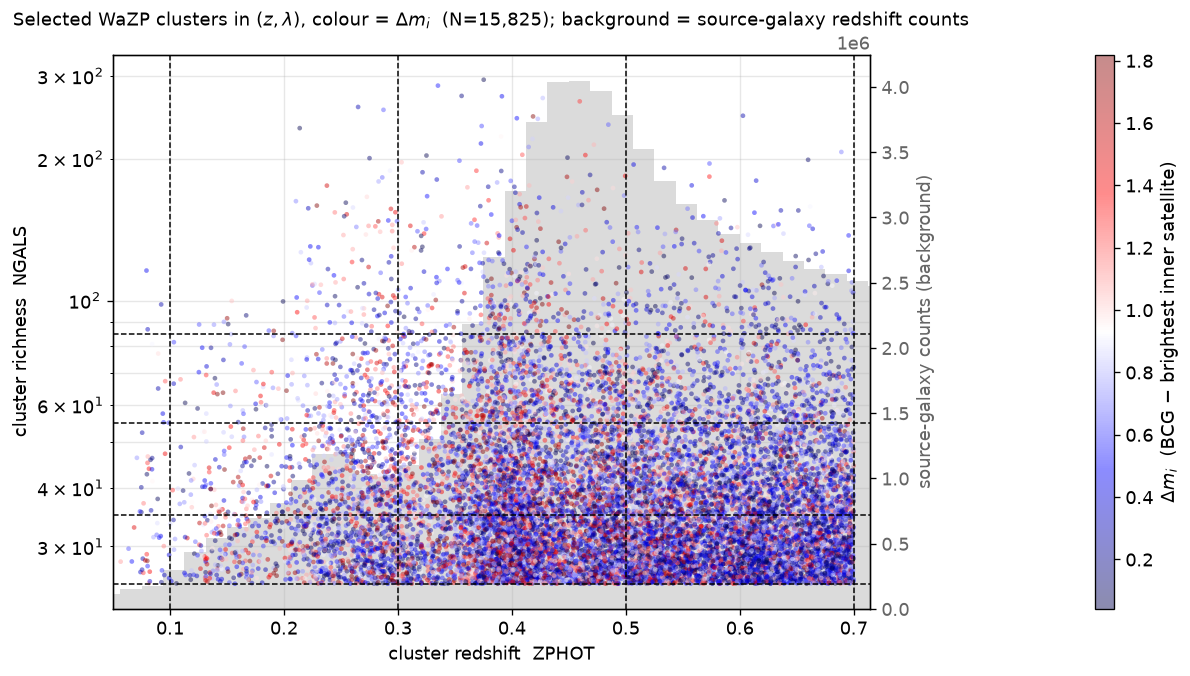

In [4]:
# Cluster sample diagnostic: (z, λ) scatter coloured by Δm with a faint
# histogram of source-galaxy redshifts in the background.  ``seismic`` puts
# red at the high-Δm end so the colour mapping matches the dm_colors dict
# (crimson = high Δm) used by the §9 and §10 plots below.
fig, ax = plt.subplots(figsize=(11, 6))

# ── background: source-galaxy z histogram on a twin y axis ─────────────────
# Skipped when SIMS=True (no source catalogue loaded; bgs are pre-computed).
ax_src = ax.twinx()
if not SIMS and SR_Z is not None:
    src_mask = (SR_Z >= 0.0) & (SR_Z <= 1.5)
    ax_src.hist(SR_Z[src_mask], bins=80, range=(0.0, 1.5),
                color='0.75', alpha=0.55, edgecolor='none', zorder=0)
    ax_src.set_ylabel('source-galaxy counts (background)', color='0.4')
    ax_src.tick_params(axis='y', labelcolor='0.4')
else:
    ax_src.set_ylabel('source-galaxy counts (skipped in SIMS mode)',
                      color='0.6')
    ax_src.set_yticks([])
ax_src.set_zorder(0)

# ── foreground: cluster scatter ────────────────────────────────────────────
ax.set_zorder(1)
ax.patch.set_visible(False)

dm_vals     = np.asarray(wazp['DELTA_M_I'], dtype=float)
vmin, vmax  = np.percentile(dm_vals, [2, 98])
sc = ax.scatter(wazp['ZPHOT'], wazp['NGALS'], c=dm_vals,
                cmap='seismic', s=8, vmin=vmin, vmax=vmax,
                alpha=0.45, edgecolor='none', zorder=2)

# ── bin-edge guides ────────────────────────────────────────────────────────
# z_edges from §2 are vertical guides; ng_edges (finite ones only) horizontal.
for ze in z_edges:
    ax.axvline(ze, color='black', lw=0.9, ls='--', alpha=1., zorder=3)
for ne in ng_edges:
    if np.isfinite(ne):
        ax.axhline(ne, color='black', lw=0.9, ls='--', alpha=1., zorder=3)

# Colorbar outside the plot area: stealing space from both axes pushes it
# past the twin axis's tick labels rather than overlaying the data area.
cbar = fig.colorbar(sc, ax=[ax, ax_src], pad=0.10, fraction=0.04, aspect=30)
cbar.set_label(r'$\Delta m_i$  (BCG − brightest inner satellite)')

ax.set_xlabel('cluster redshift  ZPHOT')
ax.set_ylabel('cluster richness  NGALS')
ax.set_yscale('log')
ax.set_xlim(0.05, max(0.7, float(np.max(wazp['ZPHOT'])) * 1.02))
ax.grid(alpha=0.3, which='both')
ax.set_title(rf'Selected{" SIM" if SIMS else " WaZP"} clusters in $(z, \lambda)$, '
             rf'colour = $\Delta m_i$  (N={len(wazp):,})' +
             ('' if SIMS else '; background = source-galaxy redshift counts'),
             fontsize=11)
plt.show()


## 3 — Per-cluster `bkg` arrays

Reuse `data/wazp_bkgs.pkl` if present; otherwise compute in parallel.

In [5]:
def bkg_worker(row):
    """Returns {ID, bkg, count} for one cluster.  When SIMS=True, bkg comes
    from the pre-computed SIM_BGS_BY_ID dict; otherwise from a BallTree
    cone query + metacal_cluster_lensing."""
    try:
        cid   = int(row['ID'])
        z_cl  = float(row['ZPHOT'])

        if SIMS:
            bkg = SIM_BGS_BY_ID.get(cid)
            if bkg is None:
                return {'ID': cid, 'bkg': None, 'count': 0}
            return {'ID': cid, 'bkg': bkg, 'count': int(bkg.shape[1])}

        ra_r  = np.deg2rad(float(row['RA']))
        dec_r = np.deg2rad(float(row['DEC']))
        D_A = float(COSMO.angular_diameter_distance(z_cl).to_value(u.Mpc))
        if D_A <= 0:
            return {'ID': cid, 'error': f'D_A={D_A}'}
        ang_r = RADIUS_MPC / D_A
        idx = TREE.query_radius(np.array([[dec_r, ra_r]]), r=ang_r)[0]
        if len(idx) == 0:
            return {'ID': cid, 'bkg': None, 'count': 0}
        sources = (
            SR_RA [idx], SR_DEC[idx], SR_Z [idx],
            SR_E1 [idx], SR_E2 [idx], SR_W [idx],
            SR_R11[idx], SR_R12[idx], SR_R21[idx], SR_R22[idx],
        )
        res = xlensing.data.metacal_cluster_lensing(
            (ra_r, dec_r, z_cl), sources, radius=RADIUS_MPC,
        )
        if res['Count'] == 0:
            return {'ID': cid, 'bkg': None, 'count': 0}
        bkg = np.array([
            np.asarray(res['Critical Density'], dtype='float32'),
            np.asarray(res['Tangential Shear'], dtype='float32'),
            np.asarray(res['Cross Shear'],      dtype='float32'),
            np.asarray(res['Weights'],          dtype='float32'),
            np.asarray(res['Radial Distance'],  dtype='float32'),
            np.asarray(res['Mult. Bias'],       dtype='float32'),
        ])
        return {'ID': cid, 'bkg': bkg, 'count': int(res['Count'])}
    except Exception as exc:
        return {'ID': int(row.get('ID', -1)), 'error': repr(exc)}


In [6]:
if os.path.exists(BKG_CACHE) and USE_CACHE:
    with open(BKG_CACHE, 'rb') as fh:
        bkg_results = pickle.load(fh)
    print(f'Loaded {len(bkg_results):,} cached bkgs from {BKG_CACHE}')
else:
    if os.path.exists(BKG_CACHE):
        print(f'USE_CACHE = False, rebuilding {BKG_CACHE} from scratch')
    input_list = [
        {'ID': int(wazp_all['ID'][i]),    'RA':   float(wazp_all['RA'][i]),
         'DEC':float(wazp_all['DEC'][i]), 'ZPHOT':float(wazp_all['ZPHOT'][i])}
        for i in range(len(wazp_all))
    ]
    print(f'Computing bkgs for {len(input_list):,} clusters with {NWORKERS} workers')
    bkg_results = []
    t0 = time.time()
    with Pool(NWORKERS) as pool:
        for i, r in enumerate(pool.imap_unordered(
                bkg_worker, input_list, chunksize=4)):
            bkg_results.append(r)
            if (i + 1) % 200 == 0 or (i + 1) == len(input_list):
                dt  = time.time() - t0
                eta = dt * (len(input_list) - i - 1) / (i + 1)
                print(f'  {i+1:>6,}/{len(input_list):,}  '
                      f'elapsed {dt/60:5.1f} min  eta {eta/60:5.1f} min',
                      flush=True)
    with open(BKG_CACHE, 'wb') as fh:
        pickle.dump(bkg_results, fh)

bkg_by_id = {r['ID']: r['bkg'] for r in bkg_results
             if r.get('bkg') is not None}
print(f'Usable bkgs: {len(bkg_by_id):,}')

USE_CACHE = False, rebuilding data/wazp_bkgs.pkl from scratch
Computing bkgs for 15,967 clusters with 15 workers
     200/15,967  elapsed   0.0 min  eta   2.3 min
     400/15,967  elapsed   0.0 min  eta   1.4 min
     600/15,967  elapsed   0.0 min  eta   1.1 min
     800/15,967  elapsed   0.1 min  eta   1.0 min
   1,000/15,967  elapsed   0.1 min  eta   0.9 min
   1,200/15,967  elapsed   0.1 min  eta   0.8 min
   1,400/15,967  elapsed   0.1 min  eta   0.8 min
   1,600/15,967  elapsed   0.1 min  eta   0.8 min
   1,800/15,967  elapsed   0.1 min  eta   0.7 min
   2,000/15,967  elapsed   0.1 min  eta   0.7 min
   2,200/15,967  elapsed   0.1 min  eta   0.7 min
   2,400/15,967  elapsed   0.1 min  eta   0.7 min
   2,600/15,967  elapsed   0.1 min  eta   0.7 min
   2,800/15,967  elapsed   0.1 min  eta   0.6 min
   3,000/15,967  elapsed   0.1 min  eta   0.6 min
   3,200/15,967  elapsed   0.2 min  eta   0.6 min
   3,400/15,967  elapsed   0.2 min  eta   0.6 min
   3,600/15,967  elapsed   0.2 min  e

## 4 — Stack the 24 cells

In [7]:
def collect_bkgs(mask):
    ids = np.asarray(wazp['ID'])[mask]
    return [bkg_by_id[int(i)] for i in ids if int(i) in bkg_by_id]

# stacked_signal now returns boost-corrected ΔΣ + full propagated covariance
# (joint cluster bootstrap of boost and signal).
stacks = {}
boost_outer = []
for i in range(3):
    for j in range(N_NG):
        for k in range(2):
            name = f'z{i}_ng{j}_dm{k}'
            mask = (z_bin == i) & (ng_bin == j) & (dm_bin == k)
            if not mask.any():
                continue
            bkgs = collect_bkgs(mask)
            if not bkgs:
                continue
            t0 = time.time()
            sigmas, boosts, boosts_cov, sigmas_cov, xigmas, xigmas_cov = (
                xlensing.data.stacked_signal(bkgs, BINS_LIMS, NBOOT)
            )

            cell_z   = np.asarray(wazp['ZPHOT'])[mask]
            cell_lam = np.asarray(wazp['NGALS'])[mask]
            cell_dm  = np.asarray(wazp['DELTA_M_I'])[mask]
            stacks[name] = {
                'z_bin':     i, 'ng_bin': j, 'dm_bin': k,
                'z_lo':      float(z_edges[i]),  'z_hi':  float(z_edges[i+1]),
                'ng_lo':     float(ng_edges[j]), 'ng_hi': float(ng_edges[j+1]),
                'dm_median': dm_median_per_cell[(i, j)],
                'z_mean':       float(cell_z.mean()),
                'lambda_mean':  float(cell_lam.mean()),
                'dm_mean':      float(cell_dm.mean()),
                'n_stacked':    len(bkgs),
                'sigmas':     np.asarray(sigmas),
                'sigmas_cov': np.asarray(sigmas_cov),
                'boosts':     np.asarray(boosts),
                'boosts_cov': np.asarray(boosts_cov),
                'xigmas':     np.asarray(xigmas),
                'xigmas_cov': np.asarray(xigmas_cov),
            }
            b_err_outer = float(np.sqrt(boosts_cov[-1, -1]))
            boost_outer.append((name, float(boosts[-1]), b_err_outer))
            print(f'{name}: ⟨z⟩={cell_z.mean():.3f}  ⟨λ⟩={cell_lam.mean():6.1f}  '
                  f'⟨Δm⟩={cell_dm.mean():.2f}  N={len(bkgs):,}  '
                  f'B_outer={boosts[-1]:.3f}±{b_err_outer:.3f}  '
                  f'({time.time()-t0:.1f}s)')

b_outer = np.array([v for _, v, _ in boost_outer])
print(f'\nOuter-bin boost factor over {len(boost_outer)} stacks:')
print(f'  median = {np.median(b_outer):.3f}  mean = {b_outer.mean():.3f}  '
      f'min = {b_outer.min():.3f}  max = {b_outer.max():.3f}')
if not (0.85 < np.median(b_outer) < 1.15):
    print('  WARNING: outer-bin boost median far from 1 — check binning / random count')

with open(STACKS_PKL, 'wb') as fh:
    pickle.dump({'radii': radii, 'bins_lims': BINS_LIMS,
                 'z_edges': z_edges, 'ng_edges': ng_edges,
                 'dm_median_per_cell': dm_median_per_cell,
                 'stacks': stacks}, fh)
n_expected = 3 * N_NG * 2
print(f'\nProduced {len(stacks)}/{n_expected} stacks, saved to {STACKS_PKL}')

z0_ng0_dm0: ⟨z⟩=0.239  ⟨λ⟩=  29.4  ⟨Δm⟩=0.34  N=432  B_outer=0.994±0.032  (1.0s)
z0_ng0_dm1: ⟨z⟩=0.232  ⟨λ⟩=  29.2  ⟨Δm⟩=1.15  N=434  B_outer=0.991±0.031  (0.8s)
z0_ng1_dm0: ⟨z⟩=0.243  ⟨λ⟩=  42.6  ⟨Δm⟩=0.36  N=276  B_outer=0.993±0.039  (0.4s)
z0_ng1_dm1: ⟨z⟩=0.237  ⟨λ⟩=  42.7  ⟨Δm⟩=1.22  N=277  B_outer=0.991±0.037  (0.5s)
z0_ng2_dm0: ⟨z⟩=0.240  ⟨λ⟩=  67.1  ⟨Δm⟩=0.41  N=117  B_outer=0.987±0.064  (0.2s)
z0_ng2_dm1: ⟨z⟩=0.248  ⟨λ⟩=  65.8  ⟨Δm⟩=1.19  N=118  B_outer=0.987±0.055  (0.2s)
z0_ng3_dm0: ⟨z⟩=0.250  ⟨λ⟩= 120.7  ⟨Δm⟩=0.38  N=52  B_outer=1.025±0.082  (0.1s)
z0_ng3_dm1: ⟨z⟩=0.255  ⟨λ⟩= 119.4  ⟨Δm⟩=1.19  N=53  B_outer=0.997±0.066  (0.1s)
z1_ng0_dm0: ⟨z⟩=0.417  ⟨λ⟩=  29.2  ⟨Δm⟩=0.33  N=1,645  B_outer=1.001±0.010  (0.7s)
z1_ng0_dm1: ⟨z⟩=0.414  ⟨λ⟩=  29.2  ⟨Δm⟩=1.14  N=1,645  B_outer=1.000±0.009  (0.7s)
z1_ng1_dm0: ⟨z⟩=0.415  ⟨λ⟩=  42.7  ⟨Δm⟩=0.36  N=1,098  B_outer=0.997±0.011  (0.4s)
z1_ng1_dm1: ⟨z⟩=0.410  ⟨λ⟩=  42.9  ⟨Δm⟩=1.17  N=1,097  B_outer=0.998±0.012  (0.5s)
z1_ng2_dm0: ⟨z⟩=0.412 

### 4.1 — Boost-factor diagnostic

$B(R)$ for all stacks. Boost has been applied to `sigmas` and `sigmas_cov` above. The 2×3 grid mirrors §5: rows = low/high Δm, columns = z slices, six richness curves per panel. Outer-bin boost should be near 1.

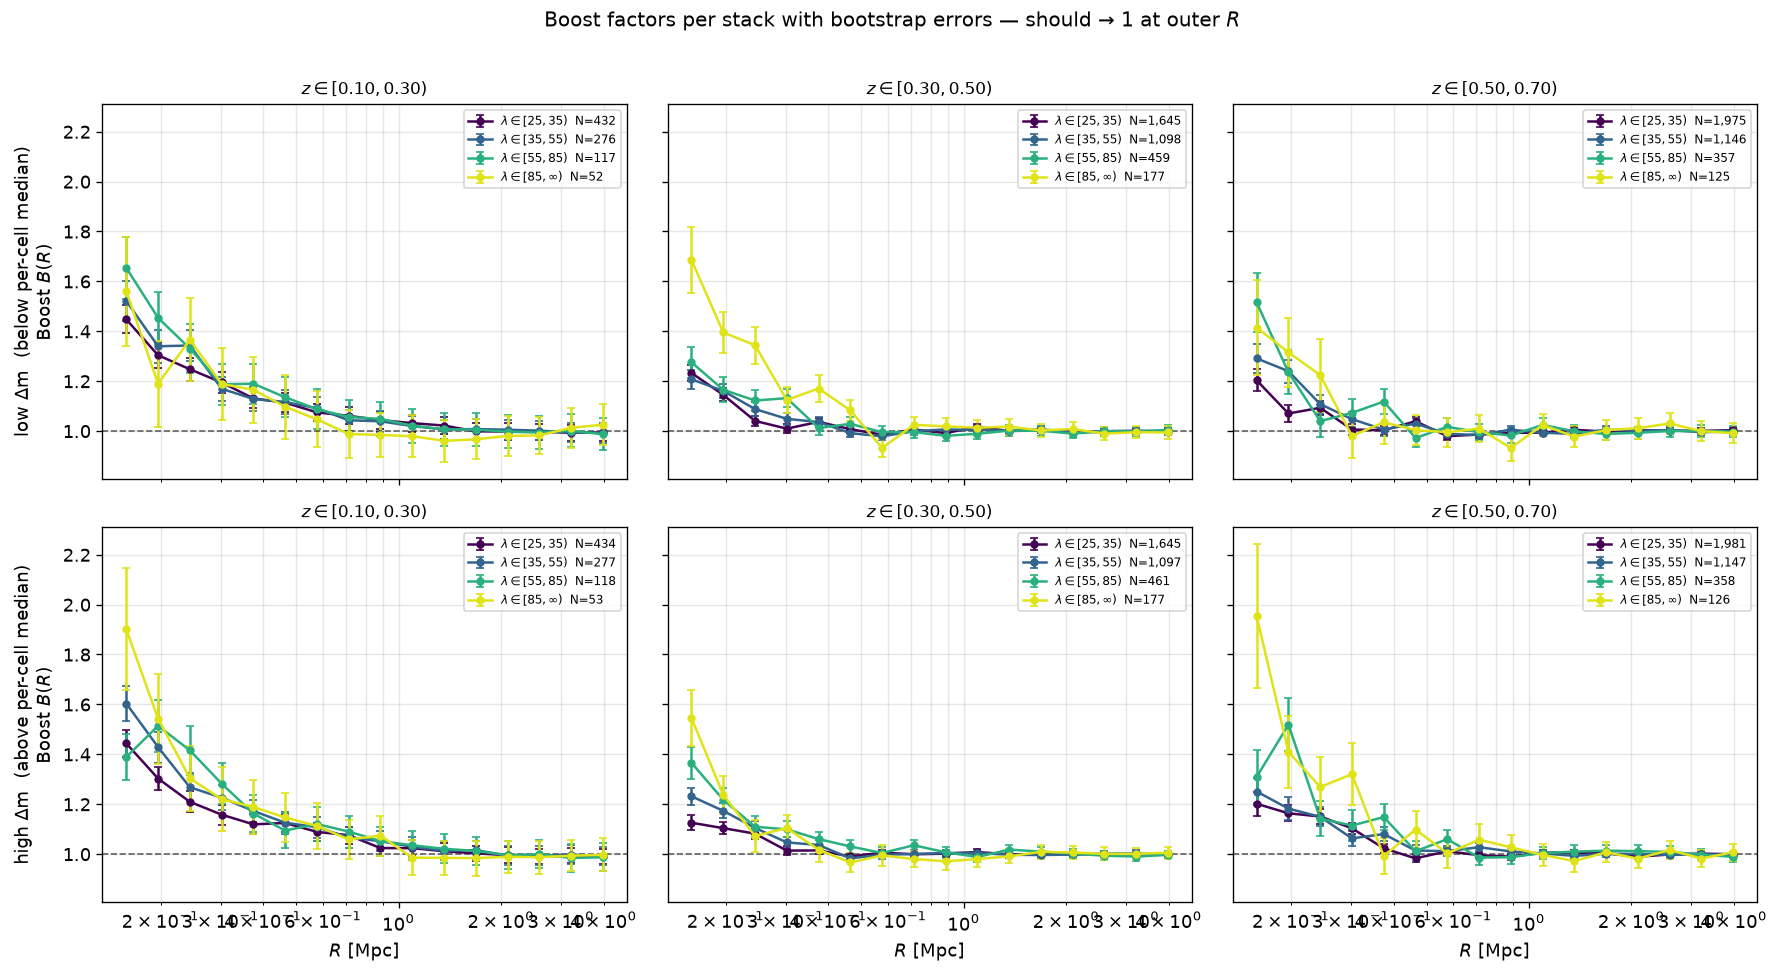

In [8]:
cmap = mpl.cm.viridis
ng_colors = [cmap(x) for x in np.linspace(0.0, 0.95, N_NG)]
dm_titles = {0: 'low Δm  (below per-cell median)',
             1: 'high Δm  (above per-cell median)'}

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
for k in range(2):
    for i in range(3):
        ax = axes[k, i]
        for j in range(N_NG):
            name = f'z{i}_ng{j}_dm{k}'
            if name not in stacks: continue
            s   = stacks[name]
            hi  = (f'{s["ng_hi"]:.0f}'
                   if np.isfinite(s["ng_hi"]) else r'\infty')
            b_err = np.sqrt(np.diag(s['boosts_cov']))
            ax.errorbar(radii, s['boosts'], yerr=b_err,
                        fmt='o-', ms=4, capsize=2.5, color=ng_colors[j],
                        label=(rf'$\lambda\in[{s["ng_lo"]:.0f},{hi})$  '
                               f'N={s["n_stacked"]:,}'))
        ax.axhline(1.0, color='k', lw=1.0, ls='--', alpha=0.6)
        ax.set_xscale('log')
        if k == 1:
            ax.set_xlabel(r'$R$ [Mpc]')
        if i == 0:
            ax.set_ylabel(rf'{dm_titles[k]}'+'\n'+r'Boost $B(R)$')
        ax.set_title(rf'$z\in[{z_edges[i]:.2f},{z_edges[i+1]:.2f})$', fontsize=10)
        ax.grid(alpha=0.3, which='both')
        ax.legend(fontsize=7, loc='upper right')

plt.suptitle('Boost factors per stack with bootstrap errors — should → 1 at outer $R$',
             fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

## 5 — Stacked profiles

Two rows (low-Δm vs high-Δm) × three columns (one per z slice). Within each panel the six NGALS curves are overlaid.

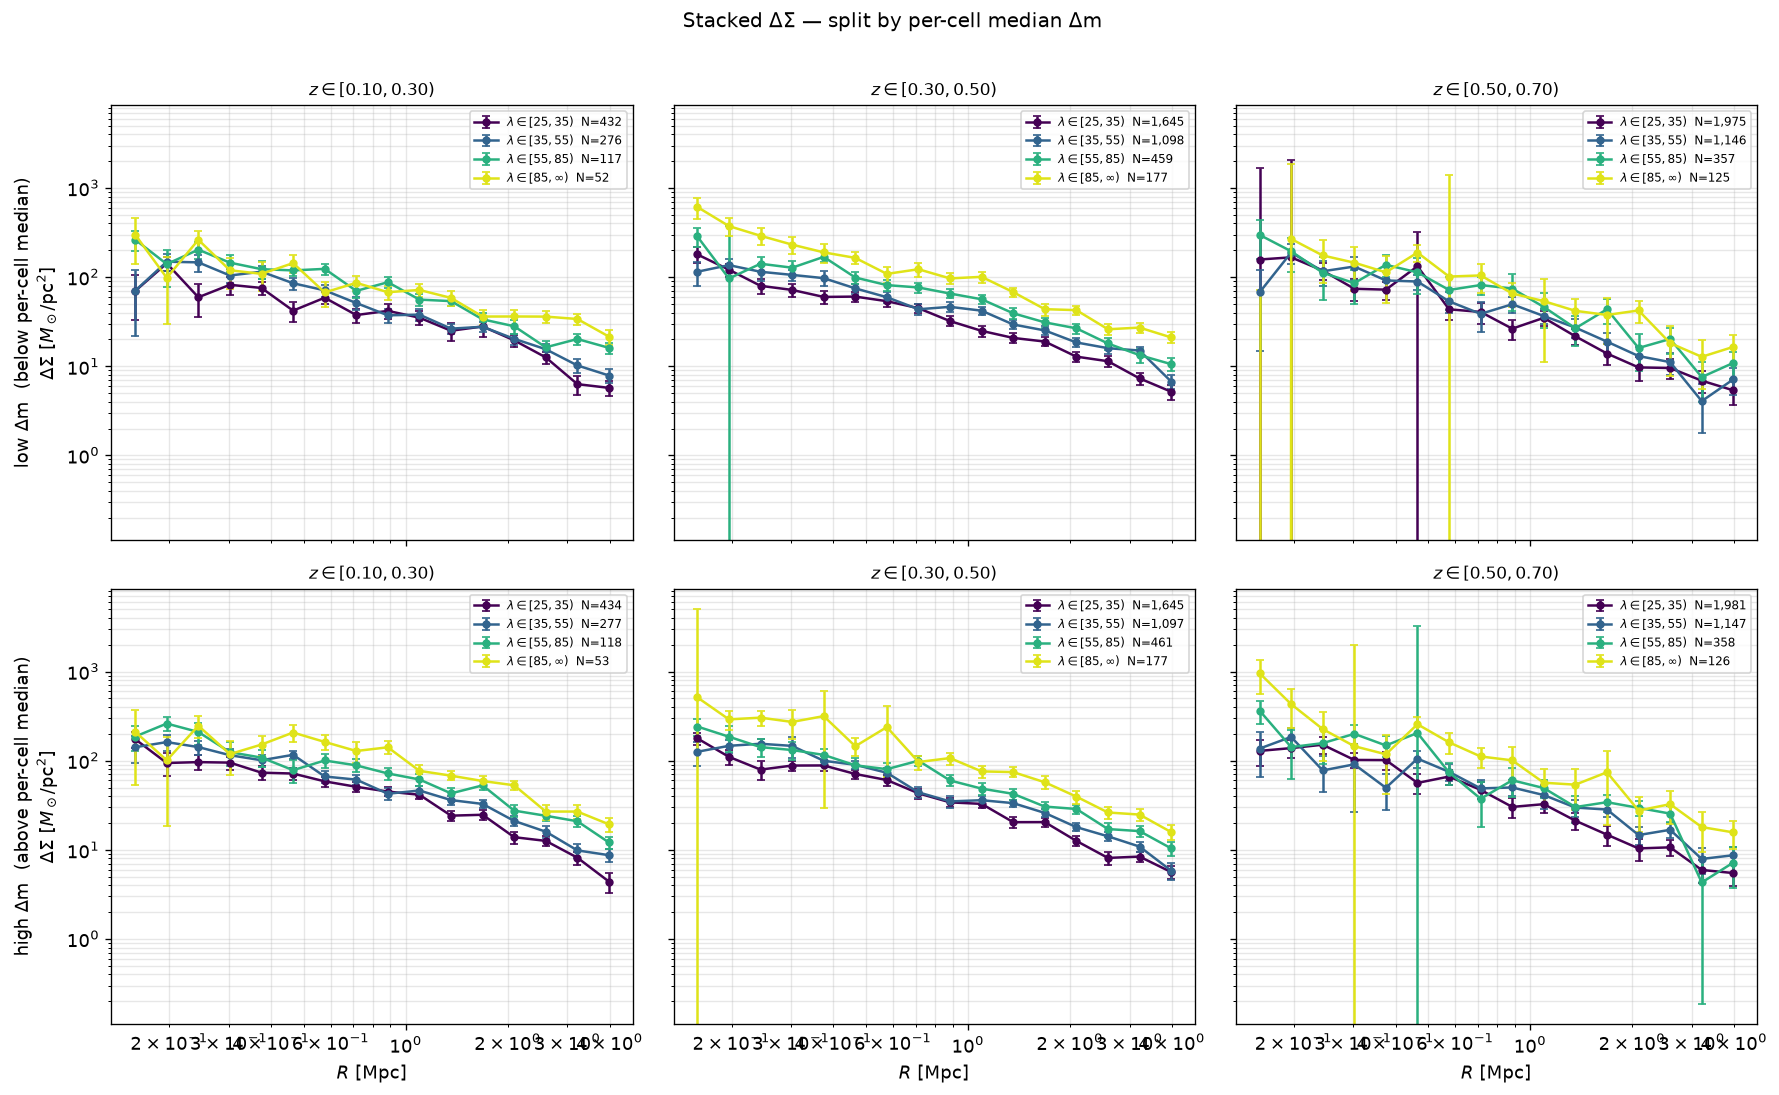

In [9]:
cmap = mpl.cm.viridis
ng_colors = [cmap(x) for x in np.linspace(0.0, 0.95, N_NG)]
dm_titles = {0: 'low Δm  (below per-cell median)',
             1: 'high Δm  (above per-cell median)'}
fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True)
for k in range(2):
    for i in range(3):
        ax = axes[k, i]
        for j in range(N_NG):
            name = f'z{i}_ng{j}_dm{k}'
            if name not in stacks: continue
            s   = stacks[name]
            err = np.sqrt(np.diag(s['sigmas_cov']))
            hi  = (f'{s["ng_hi"]:.0f}'
                   if np.isfinite(s["ng_hi"]) else r'\infty')
            ax.errorbar(radii, s['sigmas'], yerr=err,
                        fmt='o-', ms=4, capsize=2.5, color=ng_colors[j],
                        label=(rf'$\lambda\in[{s["ng_lo"]:.0f},{hi})$  '
                               f'N={s["n_stacked"]:,}'))
        ax.set_xscale('log')
        ax.set_yscale('log')
        if k == 1:
            ax.set_xlabel(r'$R$ [Mpc]')
        if i == 0:
            ax.set_ylabel(rf'{dm_titles[k]}'+'\n'+r'$\Delta\Sigma$ [$M_\odot/\mathrm{pc}^2$]')
        ax.set_title(rf'$z\in[{z_edges[i]:.2f},{z_edges[i+1]:.2f})$', fontsize=10)
        ax.grid(alpha=0.3, which='both')
        ax.legend(fontsize=7, loc='upper right')
plt.suptitle('Stacked ΔΣ — split by per-cell median Δm', fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

## 6 — NFW + miscentering fits

Free parameters per stack (4):

- `log10(M200m)` ~ $\mathcal{N}(14.5,\,2)$  (Gaussian, no hard bounds)
- `C200m`       ~ $\mathcal{N}(5,\,2)$ truncated to $[0.1,\,20]$
- `FMISS`     ~ $\mathcal{U}(0,\,1)$
- `SIGMA_OFF` ~ $\mathcal{U}(0.01,\,1.0)$  Mpc

`BCG_B_MASS` fixed at 0. The wider $\log M$ Gaussian and the truncated-normal $C$ replace the previous uniform priors so the sampler has informative central values but is still allowed to roam far from them when the data demand it.

**Parallelism**: stacks are fit **sequentially**, but each `nautilus.Sampler` receives a `multiprocess.Pool(NWORKERS)` that parallelises its likelihood evaluations within a single fit. This is more efficient than the previous strategy of fitting many stacks in parallel with single-process samplers, because hard/slow stacks no longer block whole-fit workers — they just take longer with all cores helping. Each call carries the `TIMEOUT_S` wall-clock cap; a stack that exceeds it is marked failed (no retry). Bound-splitter `ValueError`s still trigger a one-shot retry with coarser bound settings.

In [10]:
from scipy.stats import norm as sp_norm, truncnorm as sp_truncnorm

PARAM_ORDER = ['log_M', 'C', 'FMISS', 'SIGMA_OFF']

TIMEOUT_S = 300.0   # seconds — wall-clock cap passed to nautilus.Sampler.run

# Prior distributions
LOGM_MU,  LOGM_SIG = 14.5, 2.0                 # log10(M200m) ~ N(14.5, 2)
C_MU,     C_SIG    = 5.0,  3.0                 # c200m ~ N(5, 2) truncated
C_LO,     C_HI     = 0.1, 20.0
PRIOR_LOGM = sp_norm(loc=LOGM_MU, scale=LOGM_SIG)
PRIOR_C    = sp_truncnorm((C_LO - C_MU) / C_SIG,
                          (C_HI - C_MU) / C_SIG,
                          loc=C_MU, scale=C_SIG)


def _make_prior():
    p = Prior()
    p.add_parameter('log_M',     dist=PRIOR_LOGM)
    p.add_parameter('C',         dist=PRIOR_C)
    p.add_parameter('FMISS',     dist=(0.0,  1.0))
    p.add_parameter('SIGMA_OFF', dist=(0.01, 1.0))
    return p


def _run_sampler(loglike, n_live, pool=None,
                 n_points_min=None, split_threshold=100):
    """Build and run nautilus, parallelising likelihood evaluations across
    `pool` (a multiprocess.Pool or None).  Returns (sampler, success);
    success=False iff the TIMEOUT_S wall-clock fired before convergence."""
    kwargs = dict(n_live=n_live, pool=pool,
                  split_threshold=split_threshold)
    if n_points_min is not None:
        kwargs['n_points_min'] = n_points_min
    samp = Sampler(_make_prior(), loglike, **kwargs)
    success = samp.run(verbose=False, timeout=TIMEOUT_S)
    return samp, bool(success)


def _kl_div_from_sampler(samp):
    """KL(posterior ‖ prior) via the nested-sampling identity
    D_KL = <log L>_post − log Z, in nats."""
    pts, lw, log_l = samp.posterior()
    w = np.exp(lw - lw.max())
    w = w / w.sum()
    finite = np.isfinite(log_l)
    if not finite.any():
        return pts, lw, log_l, float('nan')
    kl = float(np.sum(w[finite] * log_l[finite]) - samp.log_z)
    return pts, lw, log_l, kl


def fit_one(item, pool=None):
    """
    Run nautilus on one stack with TIMEOUT_S wall-clock cap per attempt.
    `pool` is a multiprocess.Pool passed through to nautilus for parallel
    likelihood evaluation within this single fit.  Defensive NaN/Inf checks
    on the stack data and covariance prevent nautilus from hanging on
    poisoned inputs; the likelihood itself also returns ``-inf`` on any
    non-finite intermediate so the bound algorithm never sees NaN.
    """
    name, s = item
    data   = np.asarray(s['sigmas'],     dtype=float)
    cov_in = np.asarray(s['sigmas_cov'], dtype=float)
    z_eff  = float(s['z_mean'])

    common = {
        'z_mean':      s['z_mean'],
        'lambda_mean': s['lambda_mean'],
        'dm_mean':     s['dm_mean'],
        'dm_bin':      s['dm_bin'],
        'n_stacked':   s['n_stacked'],
    }

    # ── pre-flight NaN/Inf guards ────────────────────────────────────────
    if not np.all(np.isfinite(data)):
        return name, {'failed': True,
                      'error': f'NaN/Inf in sigmas ({int((~np.isfinite(data)).sum())} bins)',
                      **common}
    if not np.all(np.isfinite(cov_in)):
        return name, {'failed': True,
                      'error': 'NaN/Inf in sigmas_cov',
                      **common}
    diag_mean = float(np.mean(np.diag(cov_in)))
    if not np.isfinite(diag_mean) or diag_mean <= 0:
        return name, {'failed': True,
                      'error': f'degenerate sigmas_cov diag (mean={diag_mean})',
                      **common}
    cov_reg = cov_in + 1e-6 * np.eye(len(data)) * diag_mean
    try:
        cov_inv = np.linalg.inv(cov_reg)
    except np.linalg.LinAlgError as exc:
        return name, {'failed': True,
                      'error': f'cov inversion failed: {exc!r}',
                      **common}
    if not np.all(np.isfinite(cov_inv)):
        return name, {'failed': True,
                      'error': 'NaN/Inf in cov_inv after inversion',
                      **common}

    def loglike(p):
        try:
            M = 10.0 ** p['log_M']
            if not np.isfinite(M) or M <= 0:
                return -np.inf
            out = xlensing.model.NFW_Delta_Sigma(
                M200m=np.array([M]),
                C200m=np.array([p['C']]),
                Z=np.array([z_eff]),
                FMISS=np.array([p['FMISS']]),
                SIGMA_OFF=np.array([p['SIGMA_OFF']]),
                BCG_B_MASS=np.array([0.0]),
                radii=radii,
            )
            model_ds = np.asarray(out['Signal'][0], dtype=float)
            if not np.all(np.isfinite(model_ds)):
                return -np.inf
            res = data - model_ds
            ll = float(-0.5 * res @ cov_inv @ res)
            if not np.isfinite(ll):
                return -np.inf
            return ll
        except Exception:
            return -np.inf

    # ── run sampler with the first-attempt then bound-coarser retry ──────
    try:
        samp, ok = _run_sampler(loglike, n_live=NLIVE, pool=pool)
        if not ok:
            return name, {'failed': True,
                          'error': f'timeout > {TIMEOUT_S:.0f}s (first attempt)',
                          **common}
    except ValueError:
        try:
            samp, ok = _run_sampler(loglike,
                                    n_live=max(NLIVE * 4, 2000),
                                    pool=pool,
                                    n_points_min=50,
                                    split_threshold=400)
            if not ok:
                return name, {'failed': True,
                              'error': f'timeout > {TIMEOUT_S:.0f}s (retry)',
                              **common}
        except Exception as exc2:
            return name, {'failed': True, 'error': repr(exc2), **common}
    except Exception as exc:
        return name, {'failed': True, 'error': repr(exc), **common}

    pts, lw, log_l, kl_div = _kl_div_from_sampler(samp)
    w = np.exp(lw - lw.max()); w = w / w.sum()

    def wq(x, q):
        srt = np.argsort(x); cum = np.cumsum(w[srt])
        return float(np.interp(q, cum, x[srt]))

    mean = {p: float(np.average(pts[:, i], weights=w))
            for i, p in enumerate(PARAM_ORDER)}
    qq   = {p: (wq(pts[:, i], 0.16), wq(pts[:, i], 0.84))
            for i, p in enumerate(PARAM_ORDER)}
    return name, {
        'failed':      False,
        'mean':        mean,
        'quantiles':   qq,
        'samples':     pts.astype('float32'),
        'log_weights': lw.astype('float32'),
        'log_likes':   log_l.astype('float32'),
        'log_z':       float(samp.log_z),
        'kl_div':      kl_div,
        **common,
    }

In [11]:
# Sequential outer loop: one stack at a time.  Inside each fit, nautilus
# uses a multiprocess.Pool(NWORKERS) to parallelise its likelihood evaluations.
# Each completed fit is checkpointed immediately so a crash never costs more
# than one stack.
fits_out = {}
if os.path.exists(FITS_PKL) and USE_CACHE:
    with open(FITS_PKL, 'rb') as fh:
        fits_out = pickle.load(fh)
    print(f'Resumed {len(fits_out)} cached fits from {FITS_PKL}')
elif os.path.exists(FITS_PKL):
    print(f'USE_CACHE = False, ignoring existing {FITS_PKL} and refitting all stacks')

items_todo = [(n, s) for n, s in stacks.items() if n not in fits_out]
print(f'Fitting {len(items_todo)} stacks sequentially; '
      f'each nautilus call uses a Pool of {NWORKERS} workers')

if items_todo:
    t0 = time.time()
    with Pool(NWORKERS) as nautilus_pool:
        for k, (name, s) in enumerate(items_todo):
            name_out, out = fit_one((name, s), pool=nautilus_pool)
            fits_out[name_out] = out
            with open(FITS_PKL, 'wb') as fh:
                pickle.dump(fits_out, fh)

            dt  = time.time() - t0
            eta = dt * (len(items_todo) - k - 1) / (k + 1)
            n_clust = out.get('n_stacked', 0)
            if out.get('failed'):
                print(f'[{k+1:>2}/{len(items_todo)}] {name_out}  N={n_clust:>5,}: '
                      f"FAILED  {out['error'][:80]}  "
                      f'elapsed {dt/60:5.1f}m  eta {eta/60:5.1f}m', flush=True)
            else:
                m = out['mean']
                kl = out.get('kl_div', float('nan'))
                print(f'[{k+1:>2}/{len(items_todo)}] {name_out}  N={n_clust:>5,}: '
                      f"logM={m['log_M']:.3f}  C={m['C']:.2f}  "
                      f"fmiss={m['FMISS']:.2f}  σ_off={m['SIGMA_OFF']:.3f}  "
                      f"KL={kl:5.2f} nats  "
                      f'elapsed {dt/60:5.1f}m  eta {eta/60:5.1f}m', flush=True)

n_ok   = sum(1 for f in fits_out.values() if not f.get('failed'))
n_fail = sum(1 for f in fits_out.values() if     f.get('failed'))
print(f'\nTotal: {len(fits_out)} fits  ({n_ok} ok, {n_fail} failed) -> {FITS_PKL}')

# Summary table of KL divergences sorted by name
kls = [(n, f.get('kl_div', float('nan')), f.get('n_stacked', 0))
       for n, f in sorted(fits_out.items()) if not f.get('failed')]
if kls:
    print('\nKL(posterior ‖ prior) per stack [nats]:')
    print(f'  {"stack":<14}  {"N":>6}  {"KL":>6}')
    for n, kl, nc in kls:
        print(f'  {n:<14}  {nc:>6,}  {kl:>6.2f}')

USE_CACHE = False, ignoring existing data/wazp_mr_dm_fits.pkl and refitting all stacks
Fitting 24 stacks sequentially; each nautilus call uses a Pool of 15 workers
[ 1/24] z0_ng0_dm0  N=  432: logM=14.188  C=6.82  fmiss=0.24  σ_off=0.454  KL= 4.82 nats  elapsed   0.4m  eta   9.5m
[ 2/24] z0_ng0_dm1  N=  434: logM=14.260  C=7.76  fmiss=0.30  σ_off=0.279  KL= 5.84 nats  elapsed   0.8m  eta   9.0m
[ 3/24] z0_ng1_dm0  N=  276: logM=14.361  C=7.51  fmiss=0.24  σ_off=0.539  KL= 5.57 nats  elapsed   1.1m  eta   7.9m
[ 4/24] z0_ng1_dm1  N=  277: logM=14.458  C=7.27  fmiss=0.26  σ_off=0.383  KL= 5.57 nats  elapsed   1.8m  eta   8.9m
[ 5/24] z0_ng2_dm0  N=  117: logM=14.604  C=6.99  fmiss=0.24  σ_off=0.387  KL= 5.01 nats  elapsed   2.2m  eta   8.3m
[ 6/24] z0_ng2_dm1  N=  118: logM=14.610  C=8.39  fmiss=0.24  σ_off=0.595  KL= 5.38 nats  elapsed   2.6m  eta   7.7m
[ 7/24] z0_ng3_dm0  N=   52: logM=14.788  C=5.22  fmiss=0.35  σ_off=0.695  KL= 4.43 nats  elapsed   2.9m  eta   7.0m
[ 8/24] z0_ng3_dm

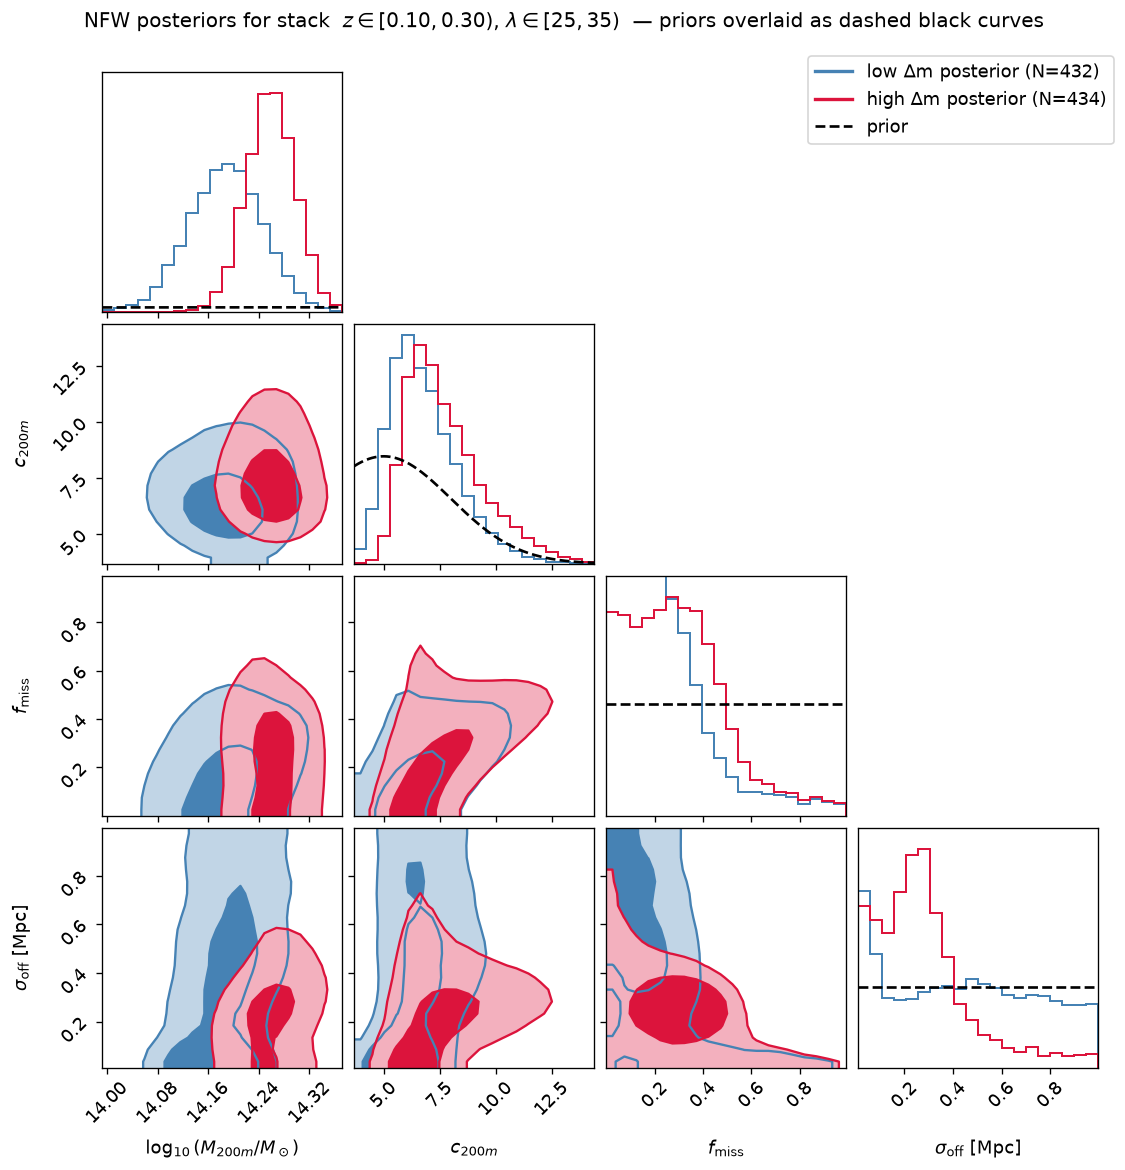

In [12]:
# Posterior corner plot for the (z, richness) cell, low-Δm vs
# high-Δm overlaid, with the priors drawn on the 1D marginals.
TARGET_Z, TARGET_NG = 0, 0
panel_names = {0: f'z{TARGET_Z}_ng{TARGET_NG}_dm0',
               1: f'z{TARGET_Z}_ng{TARGET_NG}_dm1'}
dm_corner_colors = {0: 'steelblue', 1: 'crimson'}
dm_corner_labels = {0: 'low Δm', 1: 'high Δm'}

param_labels = [r'$\log_{10}(M_{200m}/M_\odot)$',
                r'$c_{200m}$',
                r'$f_{\rm miss}$',
                r'$\sigma_{\rm off}$ [Mpc]']


def _posterior_weights(f):
    lw = np.asarray(f['log_weights'])
    w  = np.exp(lw - lw.max())
    return w / w.sum()


def _weighted_quantile_range(pts_col, w, q_lo=0.001, q_hi=0.999):
    srt = np.argsort(pts_col)
    cum = np.cumsum(w[srt])
    return (float(np.interp(q_lo, cum, pts_col[srt])),
            float(np.interp(q_hi, cum, pts_col[srt])))


usable = [name for name in panel_names.values()
          if name in fits_out and not fits_out[name].get('failed')]
if len(usable) < 2:
    print(f'Need both Δm halves fitted; have only {usable}')
else:
    # Axis ranges: union of both posteriors' 0.1%/99.9% quantile boxes,
    # then clipped to the prior support for FMISS / SIGMA_OFF.
    plot_range = []
    for i in range(len(param_labels)):
        lo_hi = []
        for name in panel_names.values():
            f   = fits_out[name]
            pts = np.asarray(f['samples'])
            w   = _posterior_weights(f)
            lo_hi.append(_weighted_quantile_range(pts[:, i], w))
        lo = min(a for a, _ in lo_hi)
        hi = max(b for _, b in lo_hi)
        plot_range.append((lo, hi))
    plot_range[2] = (max(plot_range[2][0], 0.0),  min(plot_range[2][1], 1.0))
    plot_range[3] = (max(plot_range[3][0], 0.01), min(plot_range[3][1], 1.0))

    fig = None
    for k, name in panel_names.items():
        f   = fits_out[name]
        pts = np.asarray(f['samples'])
        w   = _posterior_weights(f)
        ckw = dict(
            labels=param_labels,
            color=dm_corner_colors[k],
            weights=w,
            range=plot_range,
            hist_kwargs={'density': True, 'lw': 1.2},
            plot_datapoints=False,
            fill_contours=True,
            levels=(0.39, 0.86),     # 1σ / 2σ for a 2D Gaussian
            smooth=1.0,
            contour_kwargs={'linewidths': 1.4},
        )
        fig = (corner.corner(pts, **ckw) if fig is None
               else corner.corner(pts, fig=fig, **ckw))

    # ── overlay priors on diagonal 1D marginals ─────────────────────────────
    n = len(param_labels)
    diag_axes = [fig.axes[i * n + i] for i in range(n)]

    xs0 = np.linspace(*plot_range[0], 400)
    diag_axes[0].plot(xs0, sp_norm.pdf(xs0, loc=LOGM_MU, scale=LOGM_SIG),
                      color='black', lw=1.6, ls='--', label='prior')

    xs1 = np.linspace(*plot_range[1], 400)
    diag_axes[1].plot(
        xs1,
        sp_truncnorm.pdf(xs1, (C_LO - C_MU) / C_SIG, (C_HI - C_MU) / C_SIG,
                         loc=C_MU, scale=C_SIG),
        color='black', lw=1.6, ls='--',
    )

    xs2 = np.linspace(*plot_range[2], 400)
    diag_axes[2].plot(xs2, np.where((xs2 >= 0.0) & (xs2 <= 1.0), 1.0, 0.0),
                      color='black', lw=1.6, ls='--')

    xs3 = np.linspace(*plot_range[3], 400)
    pdf3 = np.where((xs3 >= 0.01) & (xs3 <= 1.0), 1.0 / (1.0 - 0.01), 0.0)
    diag_axes[3].plot(xs3, pdf3, color='black', lw=1.6, ls='--')

    from matplotlib.lines import Line2D
    n0 = fits_out[panel_names[0]]['n_stacked']
    n1 = fits_out[panel_names[1]]['n_stacked']
    fig.legend(
        handles=[
            Line2D([0], [0], color=dm_corner_colors[0], lw=2,
                   label=f'low Δm posterior (N={n0:,})'),
            Line2D([0], [0], color=dm_corner_colors[1], lw=2,
                   label=f'high Δm posterior (N={n1:,})'),
            Line2D([0], [0], color='black', lw=1.6, ls='--',
                   label='prior'),
        ],
        loc='upper right', bbox_to_anchor=(0.98, 0.98),
        fontsize=11, frameon=True,
    )

    s  = stacks[panel_names[0]]
    hi = f'{s["ng_hi"]:.0f}' if np.isfinite(s['ng_hi']) else r'\infty'
    fig.suptitle(
        rf'NFW posteriors for stack  '
        rf'$z\in[{s["z_lo"]:.2f},{s["z_hi"]:.2f})$, '
        rf'$\lambda\in[{s["ng_lo"]:.0f},{hi})$  '
        '— priors overlaid as dashed black curves',
        fontsize=12, y=1.01,
    )
    plt.show()


## 7 — M–λ power-law fits per Δm group

For each group (`dm=0` low / `dm=1` high) we run a weighted linear regression on

$$\log_{10} M_{200m} = \log_{10} M_0 + \alpha\,\log_{10}(\lambda/\lambda_{\rm piv}) + \beta\,\log_{10}((1+z)/(1+z_{\rm piv}))$$

with weights $1/\sigma_{\log M}^2$ (16/84 posterior half-width per stack). The analytic Gaussian posterior on $(\log M_0, \alpha, \beta)$ feeds the contour plot.

In [13]:
LAM_PIV, Z_PIV = 40.0, 0.35
MIN_N_FOR_FIT  = 10
N_DRAWS        = 1000   # bootstrap iterations + draws per stack


def distribution_linear_fit(X_per_stack, Y_per_stack, Nboot=1000, rng=None):
    """
    Multivariate linear bootstrap fit Y = X·β + intercept across N stacks,
    propagating the per-stack input distributions on X and Y.

    Each stack provides pre-paired samples: ``X_per_stack[k]`` has shape
    ``(n_k, d)`` and ``Y_per_stack[k]`` has shape ``(n_k,)``.  Pairing is
    the caller's responsibility — if X and Y are jointly distributed
    within a stack (e.g. M and C drawn from the same nautilus posterior),
    index them with the same indices into the chain before passing them
    in; otherwise draw them independently and zip them into paired arrays
    of equal length.

    For each of ``Nboot`` iterations: for every stack k, pick a uniform
    random row index ``i_k`` in ``[0, n_k)``; collect
    ``(X_per_stack[k][i_k], Y_per_stack[k][i_k])`` across stacks; fit
    ``Y = X·β + intercept`` by ordinary least squares.

    Returns ``(Nboot, d+1)`` — slopes ``β_1, …, β_d`` and intercept per
    iteration.  Use percentiles along axis 0 for marginal credible
    intervals and ``np.cov(.T)`` for the joint posterior covariance.
    """
    rng = np.random.default_rng() if rng is None else rng
    N = len(X_per_stack)
    if N == 0 or N != len(Y_per_stack):
        raise ValueError(
            f'X_per_stack/Y_per_stack must have same nonzero length '
            f'(got {N} and {len(Y_per_stack)})')

    sizes = np.empty(N, dtype=int)
    d = None
    for k in range(N):
        Xk = np.atleast_2d(np.asarray(X_per_stack[k], dtype=float))
        Yk = np.atleast_1d(np.asarray(Y_per_stack[k], dtype=float))
        if Xk.shape[0] != Yk.shape[0]:
            raise ValueError(
                f'stack {k}: X has {Xk.shape[0]} rows, Y has {Yk.shape[0]}')
        sizes[k] = Xk.shape[0]
        if d is None:
            d = Xk.shape[1]
        elif d != Xk.shape[1]:
            raise ValueError(
                f'stack {k}: X has {Xk.shape[1]} predictor cols, expected {d}')

    params_boot = np.full((Nboot, d + 1), np.nan)
    Xb = np.empty((N, d))
    Yb = np.empty(N)
    for b in range(Nboot):
        idxs = rng.integers(0, sizes)
        for k in range(N):
            Xb[k] = X_per_stack[k][idxs[k]]
            Yb[k] = Y_per_stack[k][idxs[k]]
        try:
            params, *_ = np.linalg.lstsq(
                np.column_stack([Xb, np.ones(N)]), Yb, rcond=None,
            )
            params_boot[b] = params
        except np.linalg.LinAlgError:
            pass
    return params_boot


def weighted_posterior_indices(log_w, n_draw, rng):
    """Draw n_draw indices into a nautilus weighted posterior."""
    w = np.exp(log_w - log_w.max())
    w = w / w.sum()
    return rng.choice(len(log_w), size=n_draw, p=w)


def build_stack_cluster_arrays(stacks, wazp_tab, z_bin, ng_bin, dm_bin):
    """Per-stack arrays of cluster (lambda, z), keyed by stack name."""
    out = {}
    for name, st in stacks.items():
        i, j, k = st['z_bin'], st['ng_bin'], st['dm_bin']
        mask = (z_bin == i) & (ng_bin == j) & (dm_bin == k)
        out[name] = {
            'lambda': np.asarray(wazp_tab['NGALS'])[mask].astype(float),
            'z':      np.asarray(wazp_tab['ZPHOT'])[mask].astype(float),
        }
    return out


cluster_arr = build_stack_cluster_arrays(stacks, wazp, z_bin, ng_bin, dm_bin)
rng = np.random.default_rng(42)


def build_pairs_M_lambda(fits, dm_bin_value, min_n, rng, N_draws):
    """Pre-paired (X, Y) samples per stack for the M–λ fit.

    Per stack, draw N_draws independent triples (λ, z, log M):
      - (λ, z) uniform from the cluster catalog rows in the stack,
      - log M weighted from the nautilus posterior chain.
    These two sources are independent within a stack → independent draws
    here, then zipped into paired arrays of length N_draws.
    """
    X_per_stack, Y_per_stack, names_used = [], [], []
    for name, f in fits.items():
        if f.get('dm_bin') != dm_bin_value: continue
        if f.get('failed', False): continue
        if f.get('n_stacked', 0) < min_n: continue
        lam_clu = cluster_arr[name]['lambda']
        z_clu   = cluster_arr[name]['z']
        if len(lam_clu) == 0: continue
        cluster_idx = rng.integers(0, len(lam_clu), size=N_draws)
        lam_samp = lam_clu[cluster_idx]
        z_samp   = z_clu[cluster_idx]

        pts = np.asarray(f['samples'])              # (n_post, 4)
        lw  = np.asarray(f['log_weights'])
        idx_post  = weighted_posterior_indices(lw, N_draws, rng)
        logM_samp = pts[idx_post, PARAM_ORDER.index('log_M')]

        X = np.column_stack([
            np.log10(lam_samp / LAM_PIV),
            np.log10((1.0 + z_samp) / (1.0 + Z_PIV)),
        ])
        Y = logM_samp.astype(float)
        X_per_stack.append(X)
        Y_per_stack.append(Y)
        names_used.append(name)
    return X_per_stack, Y_per_stack, names_used


all_fits     = list(fits_out.items())
n_failed_all = sum(1 for _, f in all_fits if f.get('failed'))
n_lowN_all   = sum(1 for _, f in all_fits
                   if not f.get('failed') and f.get('n_stacked', 0) < MIN_N_FOR_FIT)
print(f'Excluded from M–λ fits: {n_failed_all} failed + '
      f'{n_lowN_all} with N<{MIN_N_FOR_FIT}')

ml_fits = {}
for dm_k in (0, 1):
    X_per_stack, Y_per_stack, names_used = build_pairs_M_lambda(
        fits_out, dm_k, MIN_N_FOR_FIT, rng, N_draws=N_DRAWS,
    )
    if len(X_per_stack) < 4:
        print(f'dm={dm_k}: only {len(X_per_stack)} usable stacks, skipping')
        continue
    params_boot = distribution_linear_fit(
        X_per_stack, Y_per_stack, Nboot=N_DRAWS, rng=rng,
    )
    mean_v = np.nanmean(params_boot, axis=0)
    cov    = np.cov(params_boot.T, ddof=1)
    sigma  = np.sqrt(np.diag(cov))
    ml_fits[dm_k] = {
        'mean':        {'alpha': float(mean_v[0]),
                        'beta':  float(mean_v[1]),
                        'logM0': float(mean_v[2])},
        'cov':         cov,
        'sigma':       sigma,
        'samples':     params_boot.astype('float32'),  # (Nboot, 3) — [α, β, logM0]
        'n_stacks':    len(X_per_stack),
        'stacks_used': names_used,
        'n_draws':     N_DRAWS,
    }
    print(f'dm={dm_k}  ({"low" if dm_k==0 else "high"} Δm):  '
          f'log M0 = {mean_v[2]:+.3f} ± {sigma[2]:.3f}   '
          f'α = {mean_v[0]:+.3f} ± {sigma[0]:.3f}   '
          f'β = {mean_v[1]:+.3f} ± {sigma[1]:.3f}   '
          f'(N={len(X_per_stack)} stacks, {N_DRAWS} bootstraps)')

with open(ML_PKL, 'wb') as fh:
    pickle.dump({'lam_piv': LAM_PIV, 'z_piv': Z_PIV,
                 'min_n_for_fit': MIN_N_FOR_FIT,
                 'n_draws':       N_DRAWS,
                 'ml_fits':       ml_fits}, fh)

Excluded from M–λ fits: 0 failed + 0 with N<10
dm=0  (low Δm):  log M0 = +14.317 ± 0.028   α = +0.925 ± 0.138   β = -1.486 ± 0.604   (N=12 stacks, 1000 bootstraps)
dm=1  (high Δm):  log M0 = +14.361 ± 0.024   α = +0.940 ± 0.122   β = -1.350 ± 0.525   (N=12 stacks, 1000 bootstraps)


## 8 — Contour plot in $(\log M_0,\,\alpha,\,\beta)$

We draw 20 000 samples from each group's Gaussian posterior (mean + covariance from the weighted least squares) and overlay them in a corner-style figure to compare the two Δm samples.

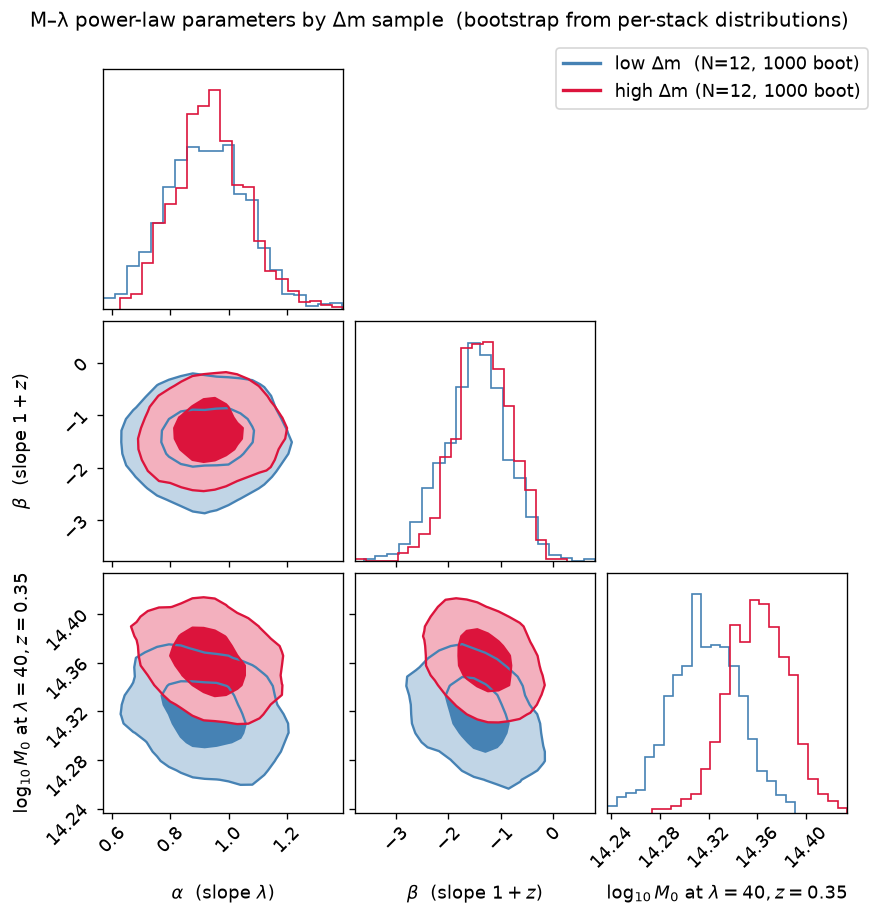


  Δ alpha (high − low) = +0.015 ± 0.185   (+0.08 σ)
  Δ  beta (high − low) = +0.136 ± 0.800   (+0.17 σ)
  Δ logM0 (high − low) = +0.044 ± 0.037   (+1.18 σ)


In [14]:
# The bootstrap distribution from distribution_linear_fit IS the posterior
# on (α, β, log M0) — we feed it straight into corner.corner instead of
# drawing from an analytic Gaussian.
param_names = ['alpha', 'beta', 'logM0']
labels = [r'$\alpha$  (slope $\lambda$)',
          r'$\beta$  (slope $1+z$)',
          rf'$\log_{{10}} M_0$ at $\lambda={LAM_PIV:.0f}, z={Z_PIV:.2f}$']

if 0 in ml_fits and 1 in ml_fits:
    samples_low  = np.asarray(ml_fits[0]['samples'], dtype=float)
    samples_high = np.asarray(ml_fits[1]['samples'], dtype=float)
    samples_low  = samples_low [np.all(np.isfinite(samples_low),  axis=1)]
    samples_high = samples_high[np.all(np.isfinite(samples_high), axis=1)]

    fig = corner.corner(
        samples_low, labels=labels, color='steelblue',
        hist_kwargs={'density': True}, plot_datapoints=False,
        fill_contours=True, levels=(0.39, 0.86),  # 1σ / 2σ for 2D Gaussian
        smooth=1.0, contour_kwargs={'linewidths': 1.4},
    )
    corner.corner(
        samples_high, color='crimson',
        hist_kwargs={'density': True}, plot_datapoints=False,
        fill_contours=True, levels=(0.39, 0.86),
        smooth=1.0, contour_kwargs={'linewidths': 1.4},
        fig=fig,
    )
    from matplotlib.lines import Line2D
    fig.legend(
        handles=[Line2D([0],[0], color='steelblue', lw=2,
                        label=(f'low Δm  (N={ml_fits[0]["n_stacks"]}, '
                               f'{len(samples_low)} boot)')),
                 Line2D([0],[0], color='crimson',  lw=2,
                        label=(f'high Δm (N={ml_fits[1]["n_stacks"]}, '
                               f'{len(samples_high)} boot)'))],
        loc='upper right', bbox_to_anchor=(0.98, 0.98), fontsize=11, frameon=True,
    )
    fig.suptitle('M–λ power-law parameters by Δm sample  '
                 r'(bootstrap from per-stack distributions)',
                 fontsize=12, y=1.01)
    plt.show()

    print()
    for p in param_names:
        m0 = ml_fits[0]['mean'][p];  m1 = ml_fits[1]['mean'][p]
        s0 = ml_fits[0]['sigma'][param_names.index(p)]
        s1 = ml_fits[1]['sigma'][param_names.index(p)]
        diff       = m1 - m0
        sigma_diff = np.sqrt(s0**2 + s1**2)
        print(f'  Δ{p:>6} (high − low) = {diff:+.3f} ± {sigma_diff:.3f}   '
              f'({diff/sigma_diff:+.2f} σ)')
else:
    print('Need both Δm groups fitted to draw the contour comparison.')

## 9 — Mass–richness data + best-fit power laws

Per-stack $\log_{10}M$ vs $\lambda$ in three panels (one per z slice), with the two Δm groups overlaid in blue (low) and red (high). Filled circles are the stacks used in the fit; open `×` markers are stacks dropped by the $N \ge 10$ rule. The solid lines are the joint power law from §7 evaluated at each panel's mean $z$.

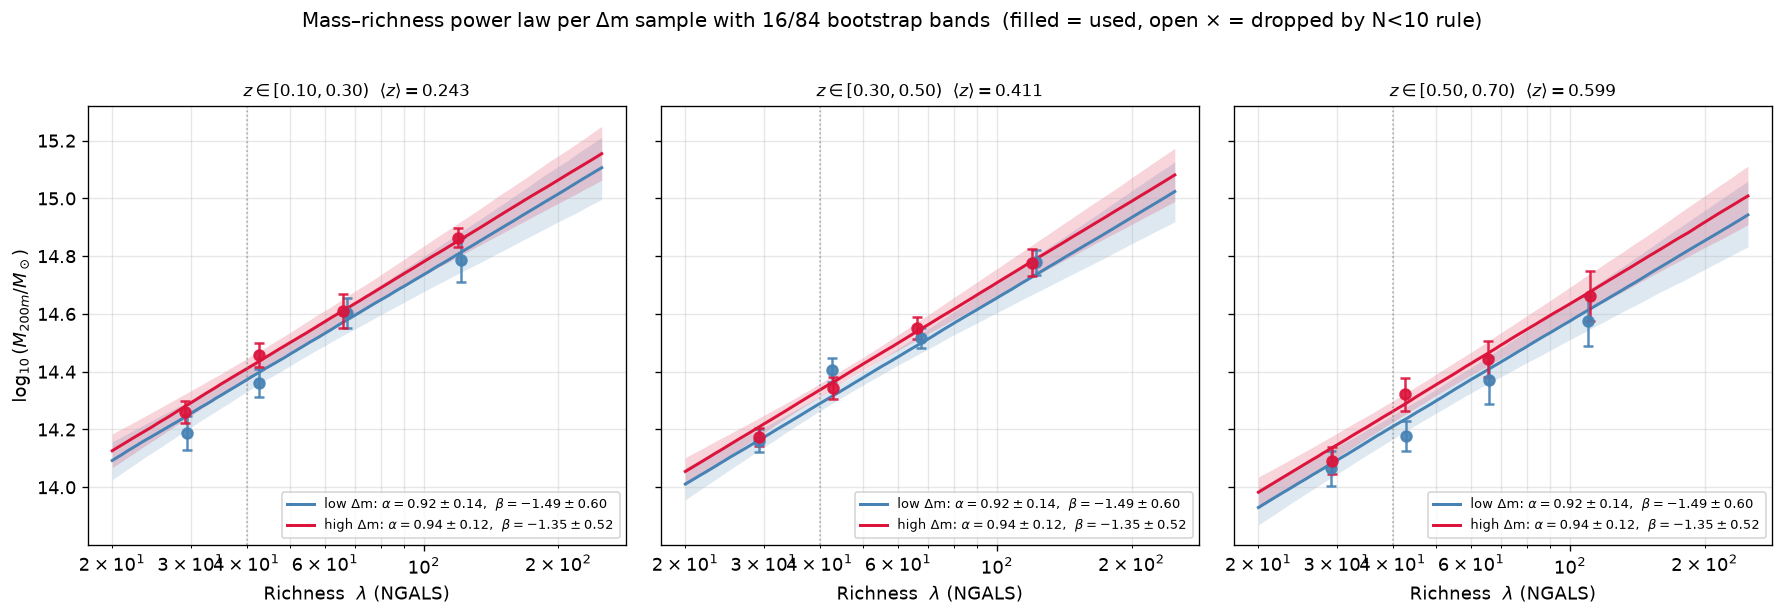

In [15]:
dm_colors = {0: 'steelblue', 1: 'crimson'}
dm_labels = {0: 'low Δm', 1: 'high Δm'}

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
lam_smooth = np.geomspace(20, 250, 100)
x_lam      = np.log10(lam_smooth / LAM_PIV)

for i in range(3):
    ax = axes[i]
    # Mean z of stacks in this z-slice (across both Δm groups, used or not)
    z_in_slice = [f['z_mean'] for n, f in fits_out.items()
                  if int(n.split('_')[0][1:]) == i and not f.get('failed')]
    z_slice_mean = (float(np.mean(z_in_slice))
                    if z_in_slice else 0.5 * (z_edges[i] + z_edges[i+1]))
    z_term = np.log10((1.0 + z_slice_mean) / (1.0 + Z_PIV))

    for k in (0, 1):
        # data points
        for name, f in fits_out.items():
            if int(name.split('_')[0][1:]) != i: continue
            if f.get('dm_bin') != k: continue
            if f.get('failed'): continue
            lam_pt  = f['lambda_mean']
            logM_pt = f['mean']['log_M']
            sig_pt  = 0.5 * (f['quantiles']['log_M'][1] - f['quantiles']['log_M'][0])
            n_clust = f['n_stacked']
            used    = n_clust >= MIN_N_FOR_FIT
            ax.errorbar(lam_pt, logM_pt, yerr=sig_pt,
                        fmt='o' if used else 'x',
                        ms=6 if used else 9,
                        mew=1.5 if used else 2,
                        color=dm_colors[k],
                        markerfacecolor=dm_colors[k] if used else 'none',
                        capsize=3, alpha=0.9 if used else 0.6)
        # Fit band + median line from the bootstrap distribution.
        # Each row of samples is (α, β, logM0); the central value of the
        # power law at (λ, z) is logM0 + α·log10(λ/piv) + β·log10((1+z)/(1+z_piv)).
        if k in ml_fits:
            samples_k   = np.asarray(ml_fits[k]['samples'], dtype=float)
            samples_k   = samples_k[np.all(np.isfinite(samples_k), axis=1)]
            logM_lines  = (samples_k[:, 2:3]
                           + samples_k[:, 0:1] * x_lam[None, :]
                           + samples_k[:, 1:2] * z_term)
            band_lo  = np.percentile(logM_lines, 16, axis=0)
            band_hi  = np.percentile(logM_lines, 84, axis=0)
            band_med = np.median(logM_lines, axis=0)
            ax.fill_between(lam_smooth, band_lo, band_hi,
                            color=dm_colors[k], alpha=0.18, lw=0)
            m = ml_fits[k]['mean']
            s = ml_fits[k]['sigma']
            ax.plot(lam_smooth, band_med, '-', color=dm_colors[k], lw=1.8,
                    label=(rf'{dm_labels[k]}: $\alpha={m["alpha"]:.2f}\pm{s[0]:.2f}$,  '
                           rf'$\beta={m["beta"]:.2f}\pm{s[1]:.2f}$'))
    ax.axvline(LAM_PIV, color='grey', ls=':', lw=1.0, alpha=0.6)
    ax.set_xscale('log')
    ax.set_xlabel(r'Richness  $\lambda$ (NGALS)')
    if i == 0:
        ax.set_ylabel(r'$\log_{10}(M_{200m}/M_\odot)$')
    ax.set_title(rf'$z\in[{z_edges[i]:.2f},{z_edges[i+1]:.2f})$  '
                 rf'$\langle z\rangle={z_slice_mean:.3f}$', fontsize=10)
    ax.grid(alpha=0.3, which='both')
    ax.legend(fontsize=8, loc='lower right')

plt.suptitle(rf'Mass–richness power law per Δm sample with 16/84 bootstrap bands  '
             rf'(filled = used, open × = dropped by N<{MIN_N_FOR_FIT} rule)',
             fontsize=12, y=1.02)
plt.tight_layout()
plt.show()


## 10 — Mass–concentration relation per Δm group

The per-stack NFW fits return a posterior on $C_{200m}$ alongside $\log M$. Per Δm group, fit a power-law $c$–$M$ relation with explicit redshift evolution:

$$
\log_{10} c_{200m}
\;=\;
\log_{10} c_0
\;+\;
\alpha\,\log_{10}(M_{200m}/M_{\rm piv})
\;+\;
\beta\,\log_{10}((1+z)/(1+z_{\rm piv}))
$$

with $M_{\rm piv} = 10^{14}\,M_\odot$ and $z_{\rm piv} = 0.35$, by weighted least squares. The weight is $1/\sigma_{\log c}^2$ where $\sigma_{\log c}$ is the per-stack posterior 16/84 half-width on $\log_{10} C$. Stacks with $N < 10$ are excluded (same convention as §7).

In [16]:
CMR_M_PIV  = 1e14   # Msun
CMR_Z_PIV  = 0.35
CMR_PKL    = 'data/wazp_mr_dm_cmr.pkl'


def build_pairs_c_M(fits, dm_bin_value, min_n, rng, N_draws):
    """Pre-paired (X, Y) samples per stack for the c–M fit.

    Per stack:
      - draw N_draws joint indices into the nautilus chain, keep
        (log M, C) at those indices — preserves the M–C correlation,
      - draw z independently for each draw from the cluster catalog.
    Drop any draws with non-positive C before passing on.
    """
    X_per_stack, Y_per_stack, names_used = [], [], []
    for name, f in fits.items():
        if f.get('dm_bin') != dm_bin_value: continue
        if f.get('failed', False): continue
        if f.get('n_stacked', 0) < min_n: continue
        pts = np.asarray(f['samples'])
        lw  = np.asarray(f['log_weights'])
        idx_post  = weighted_posterior_indices(lw, N_draws, rng)
        logM_samp = pts[idx_post, PARAM_ORDER.index('log_M')]
        C_samp    = pts[idx_post, PARAM_ORDER.index('C')]
        # Filter degenerate draws (truncated normal prior already enforces C>=0.1,
        # but a defensive check costs nothing).
        valid = np.isfinite(logM_samp) & np.isfinite(C_samp) & (C_samp > 0)
        if valid.sum() < 10: continue
        logM_samp = logM_samp[valid]
        logC_samp = np.log10(C_samp[valid])

        z_clu  = cluster_arr[name]['z']
        if len(z_clu) == 0: continue
        z_samp = z_clu[rng.integers(0, len(z_clu), size=len(logM_samp))]

        X = np.column_stack([
            logM_samp - np.log10(CMR_M_PIV),
            np.log10((1.0 + z_samp) / (1.0 + CMR_Z_PIV)),
        ])
        Y = logC_samp.astype(float)
        X_per_stack.append(X)
        Y_per_stack.append(Y)
        names_used.append(name)
    return X_per_stack, Y_per_stack, names_used


cmr_fits = {}
for dm_k in (0, 1):
    X_per_stack, Y_per_stack, names_used = build_pairs_c_M(
        fits_out, dm_k, MIN_N_FOR_FIT, rng, N_draws=N_DRAWS,
    )
    if len(X_per_stack) < 4:
        print(f'dm={dm_k}: only {len(X_per_stack)} usable stacks for c–M, skipping')
        continue
    params_boot = distribution_linear_fit(
        X_per_stack, Y_per_stack, Nboot=N_DRAWS, rng=rng,
    )
    mean_v = np.nanmean(params_boot, axis=0)
    cov    = np.cov(params_boot.T, ddof=1)
    sigma  = np.sqrt(np.diag(cov))
    cmr_fits[dm_k] = {
        'mean':        {'alpha': float(mean_v[0]),
                        'beta':  float(mean_v[1]),
                        'logC0': float(mean_v[2])},
        'cov':         cov,
        'sigma':       sigma,
        'samples':     params_boot.astype('float32'),  # (Nboot, 3) — [α, β, logC0]
        'n_stacks':    len(X_per_stack),
        'stacks_used': names_used,
        'n_draws':     N_DRAWS,
    }
    print(f'dm={dm_k}  ({"low" if dm_k==0 else "high"} Δm):  '
          f'log10(c0) = {mean_v[2]:+.3f} ± {sigma[2]:.3f}   '
          f'α = {mean_v[0]:+.3f} ± {sigma[0]:.3f}   '
          f'β = {mean_v[1]:+.3f} ± {sigma[1]:.3f}   '
          f'(N={len(X_per_stack)} stacks, {N_DRAWS} bootstraps)')

with open(CMR_PKL, 'wb') as fh:
    pickle.dump({'M_piv': CMR_M_PIV, 'z_piv': CMR_Z_PIV,
                 'min_n_for_fit': MIN_N_FOR_FIT,
                 'n_draws':       N_DRAWS,
                 'cmr_fits':      cmr_fits}, fh)
print(f'\nSaved c–M fits to {CMR_PKL}')

dm=0  (low Δm):  log10(c0) = +0.841 ± 0.068   α = -0.045 ± 0.158   β = +0.108 ± 0.742   (N=12 stacks, 1000 bootstraps)
dm=1  (high Δm):  log10(c0) = +0.847 ± 0.060   α = +0.053 ± 0.115   β = -0.070 ± 0.672   (N=12 stacks, 1000 bootstraps)

Saved c–M fits to data/wazp_mr_dm_cmr.pkl


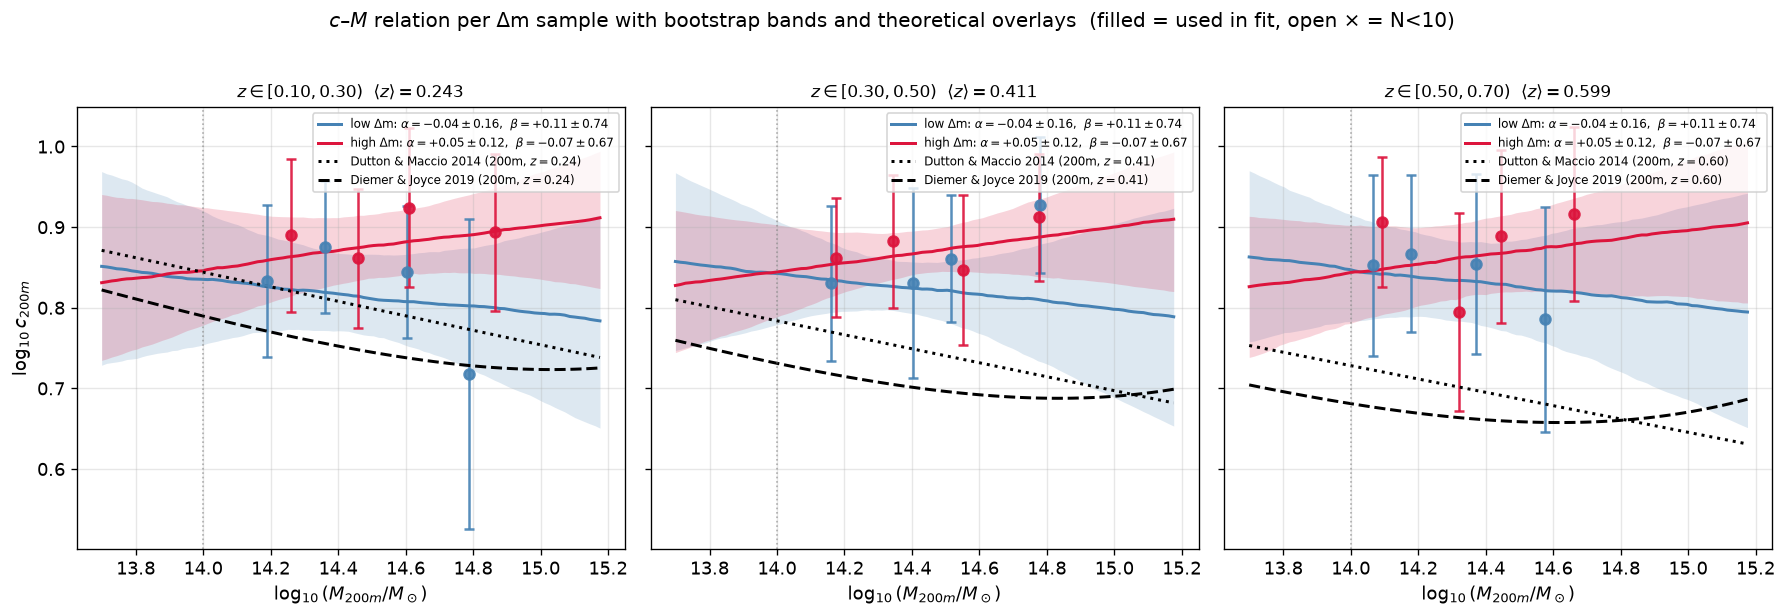

In [17]:
from colossus.cosmology import cosmology as colossus_cosmo
from colossus.halo      import concentration as colossus_conc

# Pin colossus to planck18 (matches the COSMO used elsewhere in the notebook).
# Safe to call repeatedly.
colossus_cosmo.setCosmology('planck18')
HH         = float(colossus_cosmo.getCurrent().h)

# Theoretical c-M overlays.  xlensing.sims defines r_vir using the mean matter
# density (rhoM(z) = OmegaM * rho_crit(z)), so xlensing's masses are M200m and
# concentrations are c200m.  We ask colossus for c200m(M200m) directly;
# colossus handles the mass-definition conversion internally when a model's
# native fit is at 200c (e.g. dutton14).
CMR_MODELS = ['dutton14', 'diemer19']
CMR_MDEF   = '200m'
CMR_STYLES = {
    'dutton14': (':',  'Dutton & Maccio 2014'),
    'diemer19': ('--', 'Diemer & Joyce 2019'),
    'duffy08':  ('-.', 'Duffy+ 2008'),
    'klypin16': ((0, (3, 1, 1, 1)), 'Klypin+ 2016'),
}

dm_colors = {0: 'steelblue', 1: 'crimson'}
dm_labels = {0: 'low Δm', 1: 'high Δm'}

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
M_smooth    = np.geomspace(0.5e14, 1.5e15, 100)
logM_smooth = np.log10(M_smooth)
x_m         = logM_smooth - np.log10(CMR_M_PIV)

for i in range(3):
    ax = axes[i]
    z_in_slice = [f['z_mean'] for n, f in fits_out.items()
                  if int(n.split('_')[0][1:]) == i and not f.get('failed')]
    z_slice_mean = (float(np.mean(z_in_slice))
                    if z_in_slice else 0.5 * (z_edges[i] + z_edges[i+1]))
    z_term = np.log10((1.0 + z_slice_mean) / (1.0 + CMR_Z_PIV))

    # ── per-Δm data points and bootstrap fit lines ──────────────────────────
    for k in (0, 1):
        for name, f in fits_out.items():
            if int(name.split('_')[0][1:]) != i: continue
            if f.get('dm_bin') != k: continue
            if f.get('failed'): continue
            C_mean = f['mean']['C']
            C_lo, C_hi = f['quantiles']['C']
            if C_mean <= 0 or C_lo <= 0 or C_hi <= 0: continue
            logC    = np.log10(C_mean)
            sig     = 0.5 * (np.log10(C_hi) - np.log10(C_lo))
            logM_pt = f['mean']['log_M']
            n_clust = f['n_stacked']
            used    = n_clust >= MIN_N_FOR_FIT
            ax.errorbar(logM_pt, logC, yerr=sig,
                        fmt='o' if used else 'x',
                        ms=6 if used else 9,
                        mew=1.5 if used else 2,
                        color=dm_colors[k],
                        markerfacecolor=dm_colors[k] if used else 'none',
                        capsize=3, alpha=0.9 if used else 0.6)
        # Fit band + median line from the bootstrap distribution.
        # Each row of samples is (α, β, logC0); central value of the power law
        # at (log M, z) is logC0 + α·(logM − logMpiv) + β·log10((1+z)/(1+z_piv)).
        if k in cmr_fits:
            samples_k  = np.asarray(cmr_fits[k]['samples'], dtype=float)
            samples_k  = samples_k[np.all(np.isfinite(samples_k), axis=1)]
            logC_lines = (samples_k[:, 2:3]
                          + samples_k[:, 0:1] * x_m[None, :]
                          + samples_k[:, 1:2] * z_term)
            band_lo  = np.percentile(logC_lines, 16, axis=0)
            band_hi  = np.percentile(logC_lines, 84, axis=0)
            band_med = np.median(logC_lines, axis=0)
            ax.fill_between(logM_smooth, band_lo, band_hi,
                            color=dm_colors[k], alpha=0.18, lw=0)
            m = cmr_fits[k]['mean']
            s = cmr_fits[k]['sigma']
            ax.plot(logM_smooth, band_med, '-', color=dm_colors[k], lw=1.8,
                    label=(rf'{dm_labels[k]}: $\alpha={m["alpha"]:+.2f}\pm{s[0]:.2f}$,  '
                           rf'$\beta={m["beta"]:+.2f}\pm{s[1]:.2f}$'))

    # ── theoretical c200m(M200m) overlays at the panel's mean z ─────────────
    # colossus takes M in M_sun/h.  With CMR_MDEF='200m', for models whose
    # native fit is 200c (e.g. dutton14) colossus converts internally.
    for model in CMR_MODELS:
        ls, pretty = CMR_STYLES.get(model, ('--', model))
        c_col = colossus_conc.concentration(
            M=M_smooth * HH, mdef=CMR_MDEF, z=z_slice_mean, model=model,
        )
        ax.plot(logM_smooth, np.log10(c_col),
                linestyle=ls, color='black', lw=1.8,
                label=rf'{pretty} ({CMR_MDEF}, $z={z_slice_mean:.2f}$)')

    ax.axvline(np.log10(CMR_M_PIV), color='grey', ls=':', lw=1.0, alpha=0.6)
    ax.set_xlabel(r'$\log_{10}(M_{200m}/M_\odot)$')
    if i == 0:
        ax.set_ylabel(r'$\log_{10} c_{200m}$')
    ax.set_title(rf'$z\in[{z_edges[i]:.2f},{z_edges[i+1]:.2f})$  '
                 rf'$\langle z\rangle={z_slice_mean:.3f}$', fontsize=10)
    ax.grid(alpha=0.3, which='both')
    ax.legend(fontsize=7, loc='upper right')

plt.suptitle(rf'$c$–$M$ relation per Δm sample with bootstrap bands and theoretical overlays  '
             rf'(filled = used in fit, open × = N<{MIN_N_FOR_FIT})',
             fontsize=12, y=1.02)
plt.tight_layout()
plt.show()


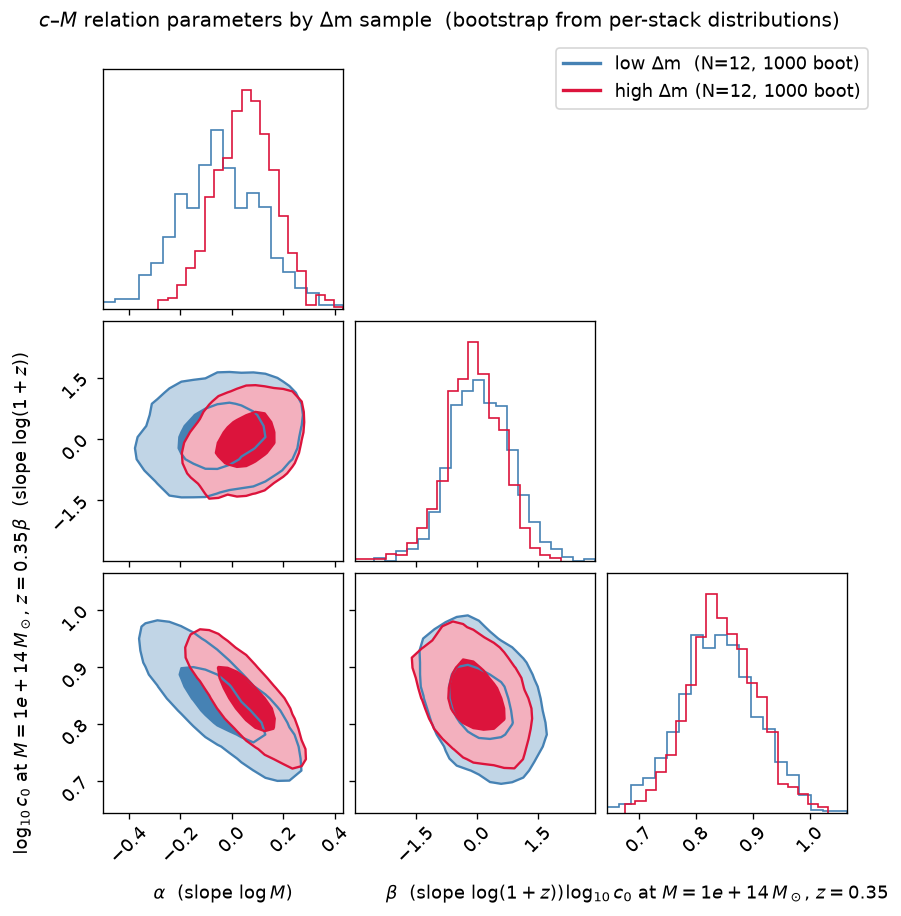


  Δ alpha (high − low) = +0.098 ± 0.195   (+0.50 σ)
  Δ  beta (high − low) = -0.178 ± 1.001   (-0.18 σ)
  Δ logC0 (high − low) = +0.007 ± 0.091   (+0.07 σ)


In [18]:
# Contour plot of c–M parameters (α, β, log c0) by Δm group, fed by the
# bootstrap distribution of fit parameters directly.
param_names = ['alpha', 'beta', 'logC0']
labels = [r'$\alpha$  (slope $\log M$)',
          r'$\beta$  (slope $\log(1+z)$)',
          rf'$\log_{{10}} c_0$ at $M={CMR_M_PIV:.0e}\,M_\odot$, $z={CMR_Z_PIV:.2f}$']

if 0 in cmr_fits and 1 in cmr_fits:
    samples_low  = np.asarray(cmr_fits[0]['samples'], dtype=float)
    samples_high = np.asarray(cmr_fits[1]['samples'], dtype=float)
    samples_low  = samples_low [np.all(np.isfinite(samples_low),  axis=1)]
    samples_high = samples_high[np.all(np.isfinite(samples_high), axis=1)]

    fig = corner.corner(
        samples_low, labels=labels, color='steelblue',
        hist_kwargs={'density': True}, plot_datapoints=False,
        fill_contours=True, levels=(0.39, 0.86),
        smooth=1.0, contour_kwargs={'linewidths': 1.4},
    )
    corner.corner(
        samples_high, color='crimson',
        hist_kwargs={'density': True}, plot_datapoints=False,
        fill_contours=True, levels=(0.39, 0.86),
        smooth=1.0, contour_kwargs={'linewidths': 1.4},
        fig=fig,
    )
    from matplotlib.lines import Line2D
    fig.legend(
        handles=[Line2D([0],[0], color='steelblue', lw=2,
                        label=(f'low Δm  (N={cmr_fits[0]["n_stacks"]}, '
                               f'{len(samples_low)} boot)')),
                 Line2D([0],[0], color='crimson',  lw=2,
                        label=(f'high Δm (N={cmr_fits[1]["n_stacks"]}, '
                               f'{len(samples_high)} boot)'))],
        loc='upper right', bbox_to_anchor=(0.98, 0.98), fontsize=11, frameon=True,
    )
    fig.suptitle(r'$c$–$M$ relation parameters by Δm sample  '
                 r'(bootstrap from per-stack distributions)',
                 fontsize=12, y=1.01)
    plt.show()

    print()
    for p in param_names:
        m0 = cmr_fits[0]['mean'][p];  m1 = cmr_fits[1]['mean'][p]
        s0 = cmr_fits[0]['sigma'][param_names.index(p)]
        s1 = cmr_fits[1]['sigma'][param_names.index(p)]
        diff       = m1 - m0
        sigma_diff = np.sqrt(s0**2 + s1**2)
        print(f'  Δ{p:>6} (high − low) = {diff:+.3f} ± {sigma_diff:.3f}   '
              f'({diff/sigma_diff:+.2f} σ)')
else:
    print('Need both Δm groups fitted to draw the contour comparison.')